# Can a model read the word class off a Bliss symbol?
### Classical machine learning vs deep learning on Blissymbolics

Blissymbolics is a written language made of symbols. People who can't speak use it to communicate, often through an AAC device (a communication aid). Every Bliss symbol belongs to a word class: a thing, an action, a person or a description. BCI, the body that looks after the language, colour codes each symbol by that class.

**My question:** can a model tell a symbol's word class from the drawing alone? And does deep learning earn its extra cost over a classical model?

**What I found, in short**
- Both approaches get there. The best deep model (a pretrained ResNet18) and the best classical model (HOG features + an SVM) score **0.936 and 0.945 macro F1** on 602 symbols they never saw. The gap is not significant (p = 0.56).
- The classical model only caught up because of **domain knowledge**. Bliss puts the word class into the drawing with small marks, and the first character of a symbol sets its category. Drawing every symbol from the left edge, so that first character always lands in the same place, lifted HOG + SVM from 0.928 to 0.961 in cross-validation.
- A small CNN trained from scratch did worst at first (0.892). One loss setting, the class weights, explained most of that.
- All the models look at the right thing. LIME shows the action and description marks are the strokes that matter most.
- Some symbols can't be classified from the drawing at all. 26 symbols beat all ten models, because their class comes from their meaning.

**How to read this notebook.** It follows the brief's life cycle: data, preprocessing, validation design, the models, evaluation, explainability, bias, ethics and deployment. Sections marked *pre-declared* were written down before they were run, so the result couldn't shape the question. Training ran partly on my laptop and partly on a Colab T4 GPU; every model saves its results, so the notebook loads them instead of retraining.

**Track:** A, Computer Vision. **Data:** BCI-AV (Blissymbolics Communication International Authorised Vocabulary), CC BY-SA 4.0.

## 0. Setup (Colab)

In [1]:
# `intent: mount Google Drive so the filtered dataset can be read` -> T14
import os                                                    # file paths, and the check for which machine we are on
ON_COLAB = os.path.exists('/content')                        # /content exists only on Colab, so this is False on the dev box
if ON_COLAB:                                                 # Drive and the install below only make sense on Colab
    !pip install -q cairosvg scikit-learn==1.8.0 networkx==3.6.1 scipy==1.17.0  # T1: cairosvg draws the SVGs. Versions pinned to the dev box: sklearn 1.8 fixed
                                                             # StratifiedGroupKFold's shuffle (#32540) and Louvain clusters can change between networkx versions
    from google.colab import drive                           # T14: Colab's helper for connecting Google Drive
    drive.mount('/content/drive')                            # T14: asks for permission, then shows Drive under /content/drive
    DATA_DIR = '/content/drive/MyDrive/bliss_wordclass/data' # where the local data/ folder is uploaded (only the filtered copy)
    RESULTS_DIR = '/content/drive/MyDrive/bliss_wordclass/results'  # saved results and charts; on Drive so they survive the Colab session
else:                                                        # running on the dev box for testing
    DATA_DIR = 'data'                                        # the data/ folder next to this notebook
    RESULTS_DIR = 'results'                                  # the results/ folder next to this notebook
os.makedirs(RESULTS_DIR, exist_ok=True)                      # make it if it is not there yet
print('Data folder:', DATA_DIR, '| Results folder:', RESULTS_DIR)  # which copy of the data this run reads, and where results go

Data folder: data | Results folder: results


In [2]:
# `intent: pick GPU if present, else CPU; print which` -> T15
import torch                                                 # PyTorch, used for the CNN and ResNet18 later
device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"  # T15: GPU ("cuda") if Colab gave us one, else the CPU
print(f"Using {device} device")                              # T15: confirm which one before any training starts

Using cpu device


In [3]:
# `intent: fix every random seed so results rerun identically` -> T16
import random                                                # Python's own random numbers
import numpy as np                                           # arrays for the images and labels
SEED = 0                                                     # one seed for the whole notebook, so every result can be rerun exactly
torch.manual_seed(SEED)                                      # T16: seeds PyTorch (weight init, shuffling) on CPU and GPU
random.seed(SEED)                                            # T16: seeds Python's random module
np.random.seed(SEED)                                         # T16: seeds NumPy (sampling the example grid, splits)
# `note: the DataLoader worker seeding from T16 (seed_worker + Generator) goes in with the DataLoader cell (T5b).`

## 1. Dataset selection and justification

I used the official **BCI-AV** release (July 2026): BCI's own spreadsheet of the authorised Bliss vocabulary plus one SVG drawing per symbol. The brief suggests sources like Kaggle or UCI. I went to the source instead, for three reasons.

- **It's the real thing.** These are the symbols AAC users actually use, maintained by the standards body, not a scraped copy.
- **The labels come with it.** BCI colour codes every symbol by word class, so I didn't have to label anything myself.
- **It's a narrow but real gap.** Machine learning has been used on Bliss images before, but to generate symbols, not to classify them. IDRC's Baby Bliss Bot trained StyleGAN on 1,217 single characters and dropped it because the results weren't good enough. The closest classification work is on a different symbol set: a 2026 Örebro University master's thesis (Karlsson, with Tobii Dynavox) predicted semantic attributes from ARASAAC pictograms using pretrained CNNs and vision-language models. I didn't find any work classifying Bliss symbols into their word classes. That comes from a bounded search, so it isn't proof that none exists.

*How I searched:* Google Scholar (October 2026, once on my own and once with my tutor during a call), plus Perplexity and Gemini, covering machine learning on Bliss symbol images, classification of AAC pictogram images, and ImageNet transfer to line drawings. The Bliss work that came up was text generation from Bliss symbols (Netzer, 2006) and symbol generation (Baby Bliss Bot). On other symbol sets I found symbol generation with a VAE and Stable Diffusion trained on FIGR-8 and ARASAAC (Caironi, 2024) and pictogram attribute prediction on ARASAAC (Karlsson, 2026). None classifies Bliss drawings by word class.

**Licence.** BCI releases BCI-AV under Creative Commons BY-SA 4.0 (checked on BCI's licensing page, https://www.blissymbolics.org/index.php/licensing, and the licence terms on choosealicense.com, October 2026). It allows any use, commercial included, and lets me change the material, as long as I credit BCI, say what I changed, and share anything I build from it under the same licence. What I changed: I rendered the SVG drawings as images, kept four of the six colour classes, and removed 223 symbols reserved for another study.

BCI's requested attribution: *The Blissymbolics Communication International Authorized Vocabulary (BCI-AV) is available at www.blissymbolics.org. The BCI-AV and other BCI Blissymbol products are copyright Blissymbolics Communication International (BCI) and made available under the Creative Commons BY-SA 4.0 licence.*

**What I kept.** The sheet has 6,556 symbols in six colours. I kept the four content-word classes and dropped WHITE (letters, numbers, small function words) and GRAY (grammar markers and social phrases). Merging those two would have made a mixed label that means nothing, so I scoped them out.

- YELLOW, things: 4,256 symbols
- RED, actions: 688
- BLUE, people: 532
- GREEN, descriptions: 539

That leaves **6,015 symbols**. Before this work began, 223 symbols reserved as the test set of a separate study of mine were removed, so the two pieces of work can't contaminate each other. One honest gap: the meanings above come from reading the data (grass, shirt and beard are YELLOW; begin and kick are RED). I haven't found BCI's own written colour key yet.

## 2. Loading the data

Two files: the label sheet (one row per symbol: ID, English gloss, colour) and a zip of the SVG drawings. The cell checks that every label has a drawing and every drawing has a label.

In [4]:
# `intent: load the label sheet and the drawings, and check they describe the same symbols` -> needs no research (pandas.read_csv, zipfile)
import zipfile                                               # read the SVG drawings straight from the zip, no unpacking
import pandas as pd                                          # tables: the label sheet
labels = pd.read_csv(os.path.join(DATA_DIR, 'labels.csv'))  # one row per symbol: id, english gloss, colour (word class)
zf = zipfile.ZipFile(os.path.join(DATA_DIR, 'bliss_svg_filtered.zip'))  # the drawings
zip_ids = {os.path.splitext(os.path.basename(n))[0] for n in zf.namelist() if n.endswith('.svg')}  # symbol IDs that have a drawing
label_ids = set(labels['id'].astype(str))                    # symbol IDs that have a label, as text to match the file names
assert label_ids == zip_ids, 'labels.csv and the zip do not hold the same symbols'  # every label has a drawing and every drawing a label
print(f'{len(label_ids):,} symbols, each with a label and a drawing.')

6,015 symbols, each with a label and a drawing.


## 3. Preprocessing

Every SVG is turned into a greyscale image the models can read. The big decision here was how to fit drawings of very different widths into one fixed size. Widths run from 20 to 1,320 units, while most symbols share a grid height of 324.

I tried the two usual tricks first and both were wrong for Bliss.
- **Stretching to a square** bends the shapes. A thin "bone" turns into a black block.
- **Shrinking to fit a square** keeps the shapes, but wide symbols get tiny, and so do their indicator marks. Those small marks are often the whole answer.

So I drew **every symbol at one shared scale**: the Bliss grid is always 64 pixels tall and the width follows, padded onto a 64 x 264 canvas. Nothing is bent and nothing is shrunk. The idea comes from IDRC's Baby Bliss Bot, who had the same problem preparing images for StyleGAN; they used a square canvas because their single characters were nearly square, while compound symbols need a wide one.

A pixel-level duplicate check runs here too. It found 3 pairs of identical drawings, one of which carries two different labels ("improve" is RED, "improvement" is YELLOW, same picture). Those pairs are kept together in the split, so they can't leak.

Later (section 6c) I found that *where* the drawing sits on the canvas matters too. That gets its own section.

In [5]:
# `intent: load the label sheet (BCI-AV# -> POS colour)` -> needs no research (pandas.read_csv). Loaded in section 2; checked here.
print(labels.shape)                                          # rows = symbols, columns = id, english, colour
assert labels['id'].is_unique, 'a symbol appears twice in labels.csv'  # one row per symbol, or counts and splits would be wrong
assert set(labels['colour']) == {'YELLOW', 'RED', 'BLUE', 'GREEN'}, set(labels['colour'])  # only the 4 content-word colours (WHITE/GRAY removed by make_exclusions.py)
labels.head()                                                # show the first few rows

(6015, 3)


,id,english,colour
0,8484,"percent,percentage,%",YELLOW
1,8485,question_mark,YELLOW
2,12322,"ability,capability,capacity,potential",YELLOW
3,12323,abortion_(induced),YELLOW
4,12325,"absorbent_material,sponge",YELLOW


In [6]:
# `intent: render each SVG to a fixed-size greyscale array` -> T1 (cairosvg) + T1b (one shared scale, pad onto a fixed canvas). Decided 2026-10-06: 64 px grid height, 64 x 264 canvas.
import io                                                    # T1: lets PIL read the PNG bytes from memory instead of a file
import cairosvg                                              # T1: draws an SVG into PNG bytes
from PIL import Image                                        # T1: image object for greyscale conversion and the canvas

GRID_PX = 64                                                 # height in pixels of one full Bliss grid (the SVG's whole viewBox height)
CANVAS_W = 264                                               # canvas width; the widest symbol is 261 px at this scale (T1b note), so nothing is shrunk

def render_symbol(svg_bytes, align='centre'):
    png_bytes = cairosvg.svg2png(                            # T1: convert the SVG into a PNG byte string
        bytestring=svg_bytes,                                # T1: the raw SVG file, already bytes from the zip
        output_width=None,                                   # T1b: width follows the drawing's own shape, so it is never stretched
        output_height=GRID_PX,                               # T1b: every symbol's grid drawn the same height = one shared scale for all
        background_color='white',                            # T1: white paper, black ink (no transparent background to deal with)
    )
    image = Image.open(io.BytesIO(png_bytes))                # T1: load the PNG bytes into a PIL image
    img_gray = image.convert('L')                            # T1b: greyscale, one channel (0 = black ink, 255 = white)
    width, height = img_gray.size                            # T1b: this symbol's own size at the shared scale
    assert width <= CANVAS_W and height == GRID_PX, (width, height)  # stop if a symbol would need shrinking or the grid height is off
    canvas = Image.new('L', (CANVAS_W, GRID_PX), 255)        # T1b: blank white canvas, the same size for every symbol
    x = int((CANVAS_W - width) / 2) if align == 'centre' else 0  # T1b: centre the symbol; 'left' (T1c, section 6c only) starts it at the left edge
    y = int((GRID_PX - height) / 2)                          # T1b: vertical offset; 0 here, the grid fills the canvas height so the baseline never moves
    canvas.paste(img_gray, (x, y))                           # T1b: copy the symbol onto the canvas without resizing it
    return np.array(canvas)                                  # hand back a plain uint8 array, shape (64, 264)

ids = labels['id'].tolist()                                  # render in label-sheet order, so images[k] matches labels.iloc[k]
images = np.stack([render_symbol(zf.read(f'bliss_svg_id/{i}.svg')) for i in ids])  # all symbols in one array: (n, 64, 264)
print(images.shape, images.dtype)                            # confirm the count and the shape

(6015, 64, 264) uint8


In [7]:
# `intent: re-check identical drawings on the RENDERED images` -> needs no research (hashlib). The byte check in T4b found 3 pairs; it misses same picture, different coordinates.
import hashlib                                               # turns each image into a short fingerprint
labels['pixel_hash'] = [hashlib.md5(img.tobytes()).hexdigest() for img in images]  # identical pixels -> identical fingerprint
dups = labels[labels.duplicated('pixel_hash', keep=False)].sort_values('pixel_hash')  # every symbol that shares its picture with another
n_groups = dups['pixel_hash'].nunique()                      # how many distinct shared pictures there are
clash = dups.groupby('pixel_hash')['colour'].nunique().gt(1).sum()  # shared pictures whose symbols carry DIFFERENT word classes
print(f'{len(dups)} symbols share a picture with another, in {n_groups} groups. {clash} of those groups disagree on the label.')
dups[['id', 'english', 'colour', 'pixel_hash']]              # list them, so each one can be checked by eye

6 symbols share a picture with another, in 3 groups. 1 of those groups disagree on the label.


,id,english,colour,pixel_hash
1689,17224,"specific,definite",GREEN,0ccd646d9e393f8567c544889f688793
5480,27032,definite,GREEN,0ccd646d9e393f8567c544889f688793
489,13667,development_(OLD),YELLOW,47ac34b9871cbe1c88176686d7481d39
5617,28012,development,YELLOW,47ac34b9871cbe1c88176686d7481d39
5517,27069,improve-(to),RED,52c3246a4d42c7001896dec3b880cdea
5518,27070,"improvement,enhancement",YELLOW,52c3246a4d42c7001896dec3b880cdea


In [8]:
# `intent: map the 4 colours to class labels (YELLOW things, RED actions, BLUE people, GREEN descriptions)` -> decided 2026-10-04, WHITE/GRAY already excluded by make_exclusions.py
# `note: colour meanings are inferred from the data (open decision 4); still needs BCI's own colour key as a source.`
CLASSES = ['YELLOW', 'RED', 'BLUE', 'GREEN']                 # fixed class order, used by every model, chart and confusion matrix
MEANING = {'YELLOW': 'things', 'RED': 'actions', 'BLUE': 'people', 'GREEN': 'descriptions'}  # plain-word meaning for charts and slides
y = labels['colour'].map({c: k for k, c in enumerate(CLASSES)}).to_numpy()  # class number per symbol: YELLOW 0, RED 1, BLUE 2, GREEN 3
assert len(y) == len(images) and not np.isnan(y.astype(float)).any()  # one label per image, none missing
print(dict(zip(CLASSES, np.bincount(y).tolist())))                  # symbols per class

{'YELLOW': 4256, 'RED': 688, 'BLUE': 532, 'GREEN': 539}


## 4. Exploratory look

Class balance (71% YELLOW), example symbols per class, and what a typical indicator mark looks like.

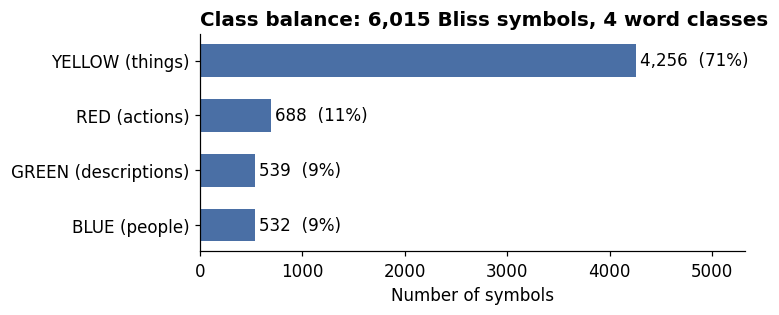

In [9]:
# `intent: bar chart of class counts` -> needs no research (matplotlib)
import matplotlib.pyplot as plt                              # plotting
plt.rcParams.update({'figure.dpi': 110, 'font.size': 11, 'axes.titlesize': 13, 'axes.titleweight': 'bold',
                     'axes.spines.top': False, 'axes.spines.right': False, 'legend.frameon': False})  # one readable style for every chart
counts = np.bincount(y)                                      # symbols per class, in CLASSES order
order = np.argsort(counts)                                   # smallest first, so the biggest bar ends up on top
fig, ax = plt.subplots(figsize=(7, 3))                       # wide and short: four bars need little height
names = [f'{CLASSES[k]} ({MEANING[CLASSES[k]]})' for k in order]  # bar names: colour code plus what it means
ax.barh(names, counts[order], color='#4a6fa5', height=0.6)   # one hue: the bars differ by size, not by identity
for row, k in enumerate(order):                              # label each bar with its count and share
    ax.text(counts[k] + 40, row, f'{counts[k]:,}  ({counts[k] / counts.sum():.0%})', va='center')  # e.g. "4,256  (71%)"
ax.set_xlim(0, counts.max() * 1.25)                          # room for the labels to the right of the longest bar
ax.set_xlabel('Number of symbols')                           # what the bar length means
ax.set_title(f'Class balance: {counts.sum():,} Bliss symbols, 4 word classes', loc='left')  # the headline
for side in ['top', 'right']:                                # drop the box edges that carry no information
    ax.spines[side].set_visible(False)
fig.tight_layout()                                           # stop labels being cut off
fig.savefig(os.path.join(RESULTS_DIR, 'class_counts.png'), dpi=200)             # keep a copy for the slides
plt.show()

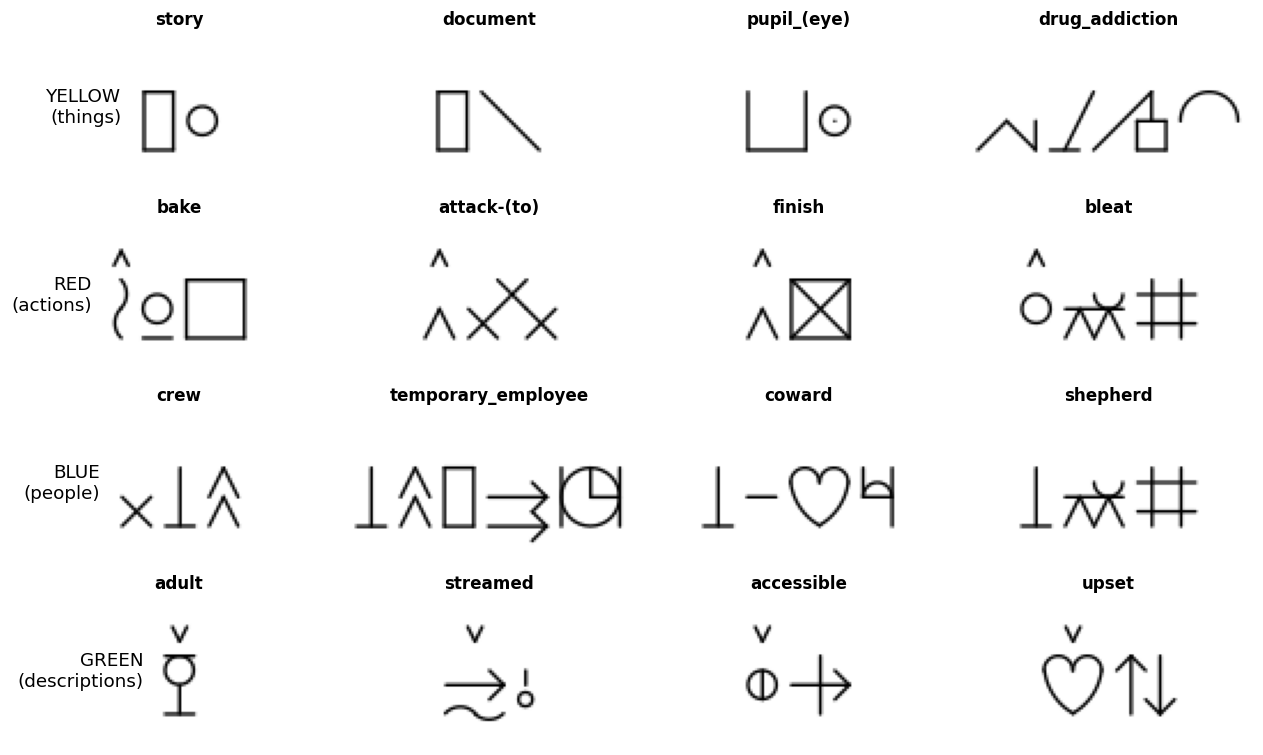

In [10]:
# `intent: grid of example symbols per class` -> needs no research (matplotlib + PIL)
rng = np.random.default_rng(SEED)                            # seeded, so the same examples appear every run
n_show = 4                                                   # examples per class
fig, axes = plt.subplots(len(CLASSES), n_show, figsize=(12, 7))  # one row per class
for r, cls in enumerate(CLASSES):                            # each class in the fixed order
    pick = rng.choice(np.flatnonzero(y == r), n_show, replace=False)  # random symbols from this class
    for c, k in enumerate(pick):                             # draw each one
        ax = axes[r, c]
        cols = np.where((images[k] < 128).any(axis=0))[0]    # columns that contain ink
        ax.imshow(images[k][:, max(0, cols.min() - 6):cols.max() + 7], cmap='gray', vmin=0, vmax=255)  # the model's input, cropped to the drawing for display
        ax.set_title(labels['english'].iloc[k].split(',')[0][:24], fontsize=11)  # its first English gloss
        ax.set_xticks([]); ax.set_yticks([])                 # pixel axes add nothing here
        for sp in ax.spines.values(): sp.set_visible(False)
    axes[r, 0].set_ylabel(f'{cls}\n({MEANING[cls]})', rotation=0, ha='right', va='center', fontsize=12)  # class name at the start of the row
fig.tight_layout()
fig.savefig(os.path.join(RESULTS_DIR, 'example_symbols.png'), dpi=200)          # keep a copy for the slides
plt.show()

In [11]:
# `intent: how much ink sits in the indicator band, per class` -> needs no research (numpy)
# `note: the band is rows 12 to 19 of the 64-row canvas, where the action and description marks are drawn (BCI Fundamental Rules,
#  clauses 6.3 and 8.1). Sections 9 and 10 use it, so it is measured here, on the drawings only.`
INDICATOR_ROWS = slice(12, 20)                               # the indicator band: 8 of the 64 rows
band_ink = images[:, INDICATOR_ROWS, :] < 128                # dark pixels inside the band, for every symbol
rows = []
for c, cls in enumerate(CLASSES):
    sel = y == c                                             # every symbol of this class
    rows.append({'class': f'{cls} ({MEANING[cls]})',
                 'symbols with any ink in the band': f'{band_ink[sel].any(axis=(1, 2)).mean():.1%}',
                 'share of band pixels that are ink': round(band_ink[sel].mean(), 4)})
band_check = pd.DataFrame(rows)
band_check

,class,symbols with any ink in the band,share of band pixels that are ink
0,YELLOW (things),11.8%,0.0015
1,RED (actions),99.9%,0.0099
2,BLUE (people),20.9%,0.0027
3,GREEN (descriptions),99.4%,0.0099


## 5. Validation design

**Test set first.** Following Nouh's advice, I split off about 10% of the symbols (602) before doing anything else. Nothing was fitted, tuned or chosen on them. They were scored once, at the very end, after the model list was locked.

**Then 5-fold cross-validation on the other 5,413.** Every model uses the exact same folds, so the comparison is fair. The folds are **stratified**: each one keeps the same class mix as the whole set, which matters when one class is 71% of the data and the others are around 10%.

**Why related symbols stay together.** Bliss compounds are built from other symbols. "abortion" contains "miscarriage", "shepherd" contains "sheep". With a plain random split, **51% of validation symbols share a part with a training symbol**. A model could score well by recognising the shared part instead of learning the word class. So I built a graph of which symbol is built from which, found tight families with Louvain community detection (2,867 families), and kept each family on one side of every split. That cuts the overlap to **3%**.

I ran every model on both splits. The gap between them tells me how much shared parts inflate a score. For most models it turned out to be tiny (0.002 to 0.004). Two were larger: the original small CNN (0.031) and the hybrid (0.016). Section 7a-2 found the CNN's gap was mostly down to its loss settings, not the shared parts.

**Two things that tripped me up.**
- An older scikit-learn (1.7.2) gave lopsided folds when shuffling. Version 1.8 fixed the bug (#32540), so the notebook pins the version and checks it.
- Five folds can't prove a difference on their own. With only 32 ways to swap 5 pairs, the smallest possible p-value is 0.0625. So my significance tests compare the two models' predictions symbol by symbol (5,413 pairs), randomly swapping each pair of predictions to see how big a gap chance alone produces. This is a paired randomisation test, the kind Yeh (2000) recommends for differences in F-score. I also correct for the number of comparisons.

In [12]:
# `intent: cluster symbols that are built from each other (T4b revised 2026-10-05); the clusters become the split groups` -> T18 (Louvain). Links come from make_exclusions.py
import networkx as nx                                        # graphs and community detection
links = pd.read_csv(os.path.join(DATA_DIR, 'links.csv'), dtype=str)  # one row per "built from" link: symbol_id is made from part_id
assert (set(links['symbol_id']) | set(links['part_id'])) <= label_ids, 'links.csv names a symbol that is not in the dataset'  # every link joins two of our symbols
ids_str = labels['id'].astype(str)                           # symbol IDs as text, matching links.csv
G = nx.Graph()                                               # undirected: "A built from B" and "B used in A" are the same tie for splitting
G.add_nodes_from(ids_str)                                    # every symbol is a node, so unlinked symbols become clusters of one
G.add_edges_from(links[['symbol_id', 'part_id']].itertuples(index=False, name=None))  # one edge per link
for _, same in labels.groupby('pixel_hash'):                 # identical drawings (found in section 3) must never sit on both sides
    same_ids = same['id'].astype(str).tolist()               # the symbols sharing this picture
    G.add_edges_from(zip(same_ids[:-1], same_ids[1:]))       # chain them together (no edge added when the picture is unique)
communities = nx.community.louvain_communities(G, seed=SEED) # T18: tight families of related symbols; seed fixed so the clusters rerun identically
cluster_of = {node: k for k, members in enumerate(communities) for node in members}  # symbol ID -> cluster number
groups = ids_str.map(cluster_of).to_numpy()                  # cluster number per symbol, in the same order as images and y
sizes = np.bincount(groups)                                  # symbols per cluster
print(f'{G.number_of_edges():,} links -> {len(communities):,} clusters. '
      f'Largest has {sizes.max()} symbols; {np.mean(sizes == 1):.0%} of clusters are a single unlinked symbol.')

3,410 links -> 2,867 clusters. Largest has 135 symbols; 85% of clusters are a single unlinked symbol.


In [13]:
# `intent: split off ~10% held-out test set FIRST, then ONE 5-fold stratified grouped CV on the rest, reused by every model` -> T4a + T4b (decided 2026-10-04, Nouh). Groups = Louvain clusters (T18)
# `note: the random 5-fold split is built on the SAME dev set as a comparison. The score gap between the two measures how much shared parts inflate results.`
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold  # T4b and T4a
import sklearn                                               # only to check the version below
assert sklearn.__version__ == '1.8.0', sklearn.__version__  # before 1.8, shuffle=True broke the class balance in StratifiedGroupKFold (fix #32540); other versions also give different folds
assert nx.__version__ == '3.6.1', nx.__version__             # the Louvain clusters must match the ones these results were built on
X_index = np.arange(len(y))                                  # the splitters only need y and groups; positions stand in for the features
outer = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=SEED)  # T4b: 10 grouped folds, so one fold is ~10% of the data
dev_idx, test_idx = next(iter(outer.split(X_index, y, groups)))  # keep the FIRST fold as the held-out test set; the other 9 are the dev set
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)  # T4b: 5 folds on the dev set, clusters never split
cv_cluster = [(dev_idx[tr], dev_idx[va])                     # convert fold positions back to positions in the full arrays
              for tr, va in sgkf.split(dev_idx, y[dev_idx], groups[dev_idx])]
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)  # T4a: plain stratified folds, ignores clusters (the comparison)
cv_random = [(dev_idx[tr], dev_idx[va]) for tr, va in skf.split(dev_idx, y[dev_idx])]  # same dev set, same positions convention
print(f'Held-out test: {len(test_idx)} symbols ({len(test_idx) / len(y):.1%}). Dev set: {len(dev_idx)} symbols, '
      f'5 cluster folds and 5 random folds.')       # test is not touched again until the final evaluation

Held-out test: 602 symbols (10.0%). Dev set: 5413 symbols, 5 cluster folds and 5 random folds.


In [14]:
# `intent: check no symbol and no group appears in both train and test of any fold` -> T4b
assert len(set(test_idx) & set(dev_idx)) == 0 and len(test_idx) + len(dev_idx) == len(y)  # test and dev are disjoint and cover every symbol
assert not set(groups[test_idx]) & set(groups[dev_idx]), 'a cluster sits in both test and dev'  # no family split across test and dev
for name, folds in [('cluster', cv_cluster), ('random', cv_random)]:  # both splits must be valid CV schemes
    assert np.array_equal(np.sort(np.concatenate([va for _, va in folds])), np.sort(dev_idx)), name  # each dev symbol validated exactly once
    for tr, va in folds:                                     # every fold
        assert not set(tr) & set(va), name                   # no symbol in both training and validation
        assert len(tr) + len(va) == len(dev_idx), name       # nothing lost and nothing from the test set
for tr, va in cv_cluster:                                    # the grouped split only
    assert not set(groups[tr]) & set(groups[va]), 'cluster split across a fold'  # no family split across train and validation
print('Leak check passed: test set sealed off, no symbol or cluster on both sides of any cluster fold.')

Leak check passed: test set sealed off, no symbol or cluster on both sides of any cluster fold.


In [15]:
# `intent: show what each split does: class balance per fold, and how many validation symbols are directly linked to a training symbol` -> needs no research (numpy + pandas)
pos = {i: k for k, i in enumerate(ids_str)}                  # symbol ID -> row position
edges = np.array([(pos[a], pos[b]) for a, b in G.edges()])   # every link as a pair of row positions
def linked_share(held, train):                               # share of held-out symbols with a direct link to a training symbol
    is_held = np.zeros(len(y), bool); is_held[held] = True   # mark the held-out side
    is_train = np.zeros(len(y), bool); is_train[train] = True  # mark the training side
    hit = np.zeros(len(y), bool)                             # will mark held-out symbols that touch training
    a, b = edges[:, 0], edges[:, 1]                          # the two ends of every link
    hit[a[is_held[a] & is_train[b]]] = True                  # link runs held-out -> training
    hit[b[is_held[b] & is_train[a]]] = True                  # link runs training -> held-out
    return hit[held].mean()                                  # fraction of held-out symbols that share a part with training
rows = []
for name, folds in [('cluster', cv_cluster), ('random', cv_random)]:
    for k, (tr, va) in enumerate(folds):
        share = np.bincount(y[va], minlength=4) / len(va)    # class mix of this validation fold
        rows.append({'split': name, 'fold': k, 'n_val': len(va), **dict(zip(CLASSES, share.round(3))),
                     'val linked to train': round(linked_share(va, tr), 3)})
share = np.bincount(y[test_idx], minlength=4) / len(test_idx)  # class mix of the held-out test set
rows.append({'split': 'held-out test', 'fold': '-', 'n_val': len(test_idx), **dict(zip(CLASSES, share.round(3))),
             'val linked to train': round(linked_share(test_idx, dev_idx), 3)})
split_table = pd.DataFrame(rows)                             # one row per fold, plus the test set
print('Overall class mix:', dict(zip(CLASSES, (np.bincount(y) / len(y)).round(3).tolist())))  # the target every fold should be near
split_table

Overall class mix: {'YELLOW': 0.708, 'RED': 0.114, 'BLUE': 0.088, 'GREEN': 0.09}


,split,fold,n_val,YELLOW,RED,BLUE,GREEN,val linked to train
0,cluster,0,1083,0.707,0.114,0.089,0.09,0.025
1,cluster,1,1083,0.707,0.114,0.089,0.09,0.030
2,cluster,2,1082,0.708,0.114,0.089,0.09,0.025
3,cluster,3,1083,0.707,0.114,0.089,0.09,0.040
4,cluster,4,1082,0.708,0.115,0.088,0.09,0.026
5,random,0,1083,0.707,0.114,0.089,0.09,0.524
6,random,1,1083,0.707,0.114,0.089,0.09,0.505
7,random,2,1083,0.707,0.114,0.089,0.09,0.502
8,random,3,1082,0.708,0.115,0.088,0.09,0.532
9,random,4,1082,0.708,0.114,0.089,0.09,0.509


## 6. Classical model: HOG + SVM

**HOG** (Histogram of Oriented Gradients) describes a picture by the direction of its edges in small patches. It's a natural fit for line drawings, which are nothing but edges. I used 9 edge directions, 8 x 8 pixel cells and 2 x 2 cell blocks, which gives 8,064 numbers per symbol. That is the default setup from Dalal and Triggs (2005), who introduced HOG. Their best setting for spotting people in photos was slightly different (3 x 3 blocks of 6 x 6 cells), so I treat theirs as a standard starting point, checked on my own data, not as settings proven for Bliss. The tutorial's 16 x 16 cells were too coarse: Bliss indicator marks are only about 5 pixels wide, and a big cell blurs them into the shape below.

**The SVM** is a support vector machine with an RBF kernel, behind a scaler, in one scikit-learn Pipeline. The Pipeline matters because the scaler is then refitted inside every training fold, so nothing leaks from validation to training. Class weights stop the 71% class from dominating.

**Hyperparameters.** C (how hard the SVM tries to fit every training symbol) and gamma (how local its decisions are) are tuned by a grid search that runs *inside* each training fold, with its own 3 inner folds. On the family split those inner folds are grouped too, or the tuning itself would leak. When a winner landed on the edge of the grid, I widened the grid and ran it again.

HOG features: (6015, 8064) in 16 s


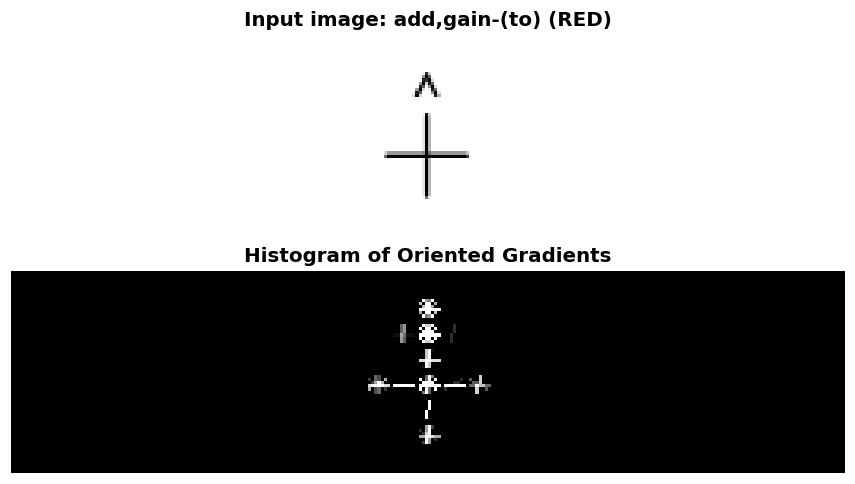

In [16]:
# `intent: extract HOG features from every image` -> T2
# `note: HOG settings 9 orientations, 8x8-pixel cells, 2x2-cell blocks (decided 2026-10-06). The page example uses 16x16 cells on a 512 px photo;
#  our indicator marks are only ~5 px, and a 16 px cell blurs them into the symbol below. A one-fold probe agreed (macro F1 0.895 at 8x8 vs
#  0.860 at 16x16; 3x3 blocks scored the same as 2x2 at twice the cost). That probe looked at cluster fold 0, so treat the choice as
#  checked on the data, not tuned blind. Source still to add: Dalal & Triggs (2005) is where 8x8 / 2x2 / 9 comes from.`
from skimage.feature import hog                              # T2: Histogram of Oriented Gradients
from skimage import exposure                                 # T2: only for drawing the HOG picture below
import time                                                  # wall-clock timing for the cost table
t0 = time.perf_counter()                                     # start the HOG timer
X_hog = np.array([hog(img,                                   # T2: one feature vector per symbol
                      orientations=9,                        # 9 edge directions per histogram
                      pixels_per_cell=(8, 8),                # one histogram per 8x8 patch: small enough to keep the indicator mark separate
                      cells_per_block=(2, 2))                # normalise contrast over 2x2 cells
                  for img in images])                        # greyscale already, so no channel_axis (the page's example is colour)
hog_seconds = time.perf_counter() - t0                       # HOG time for all symbols
print(f'HOG features: {X_hog.shape} in {hog_seconds:.0f} s')  # (symbols, features per symbol)
# `note: HOG has nothing to fit, it is the same fixed recipe for every image, so computing it once for all symbols leaks nothing.`

k = int(np.flatnonzero(y == CLASSES.index('RED'))[0])        # one action symbol, to show what HOG sees
fd, hog_image = hog(images[k], orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2), visualize=True)  # T2: also return the picture
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 4.5))      # T2: input above, HOG below (images are wide, so stack them)
ax1.axis('off')                                              # T2
ax1.imshow(images[k], cmap=plt.cm.gray)                      # T2
ax1.set_title(f"Input image: {labels['english'].iloc[k]} (RED)")  # T2
hog_image_rescaled = exposure.rescale_intensity(hog_image, in_range=(0, 10))  # T2: Rescale histogram for better display
ax2.axis('off')                                              # T2
ax2.imshow(hog_image_rescaled, cmap=plt.cm.gray)             # T2
ax2.set_title('Histogram of Oriented Gradients')             # T2
fig.tight_layout()
fig.savefig(os.path.join(RESULTS_DIR, 'hog_example.png'), dpi=200)              # keep a copy for the slides
plt.show()                                                   # T2

In [17]:
# `intent: Pipeline(scaler, SVM with class_weight); tune C/gamma inside the training fold only` -> T3, T3b
from sklearn.svm import SVC                                  # T3
from sklearn.preprocessing import StandardScaler             # T3
from sklearn.pipeline import Pipeline                        # T3
from sklearn.model_selection import GridSearchCV             # T3b
def make_svm_search(split_name, parameters=None, class_weight='balanced'):
    pipe = Pipeline([('scaler', StandardScaler()),            # T3: the scaler is refitted inside every training fold, so nothing leaks
                     ('svc', SVC(class_weight=class_weight))]) # T3: 'balanced' weights each class by n_samples / (n_classes * count), so the 71% class cannot dominate
    parameters = parameters or {'svc__C': [10, 100, 1000],                 # T3b + T3 '__' syntax: how hard the SVM tries to fit every training symbol. Widened 2026-10-06:
                                                             # the first run (C 0.1 to 100) picked 100, the top edge, in 4 of 10 folds; 0.1 and 1 never won
                  'svc__gamma': [1e-5, 1e-4, 1e-3]}          # T3b: RBF kernel width. 'scale' would be ~1.2e-4 for 8,064 standardised features, so the grid brackets it
    inner = (StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED) if split_name == 'cluster'  # T4b: inner folds keep clusters together too,
             else StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED))  # T4a: or tuning would leak on the cluster split
    return GridSearchCV(pipe, parameters, cv=inner, scoring='f1_macro', n_jobs=4)  # T3b: score by macro F1, the main metric; 4 jobs fit the dev box's memory
print(make_svm_search('cluster'))                            # show the full search set-up

GridSearchCV(cv=StratifiedGroupKFold(n_splits=3, random_state=0, shuffle=True),
             estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                       ('svc', SVC(class_weight='balanced'))]),
             n_jobs=4,
             param_grid={'svc__C': [10, 100, 1000],
                         'svc__gamma': [1e-05, 0.0001, 0.001]},
             scoring='f1_macro')


In [18]:
# `intent: out-of-fold predictions + timing` -> T3, T11 (timing with time.perf_counter, since the T11 profiler is PyTorch only)
import pickle                                                # model size = bytes of the saved model
from sklearn.metrics import f1_score                         # macro F1 per fold (full report in section 8, T7)
results = {}                                                 # every model's results land here, keyed by (model, split)
SVM_SAVED = os.path.join(RESULTS_DIR, 'svm_results.pkl')     # made on the dev box: the search takes ~2.5 h on 4 cores, far longer on Colab's 2
RERUN_SVM = False                                            # True = redo everything even when saved results exist
saved = pickle.load(open(SVM_SAVED, 'rb')) if os.path.exists(SVM_SAVED) and not RERUN_SVM else {}  # load what is already done
results.update(saved)
if ('svm', 'cluster') in results and ('svm', 'random') in results:
    print(f'Loaded saved SVM cross-validation results from {SVM_SAVED}.')
else:
    for split_name, folds in [('cluster', cv_cluster), ('random', cv_random)]:  # same folds every model will use
        oof = np.full(len(y), -1)                                # out-of-fold prediction per dev symbol; -1 = test set, never predicted here
        rec = {'fold_f1': [], 'fit_s': [], 'predict_s': [], 'best': [], 'size_mb': [], 'n_support': []}
        for k, (tr, va) in enumerate(folds):
            search = make_svm_search(split_name)                 # fresh search: nothing carried over from another fold
            t0 = time.perf_counter()
            fit_groups = {'groups': groups[tr]} if split_name == 'cluster' else {}  # only the grouped inner splitter uses groups
            search.fit(X_hog[tr], y[tr], **fit_groups)           # tune C and gamma on THIS training fold only, then refit the best on all of it
            rec['fit_s'].append(time.perf_counter() - t0)        # training cost, including the search
            t0 = time.perf_counter()
            oof[va] = search.predict(X_hog[va])                  # predict the validation fold the model never saw
            rec['predict_s'].append(time.perf_counter() - t0)    # inference cost for the whole fold
            rec['fold_f1'].append(f1_score(y[va], oof[va], average='macro'))  # this fold's score, kept for the paired test (T12)
            rec['best'].append(search.best_params_)              # which C and gamma won here
            rec['size_mb'].append(len(pickle.dumps(search.best_estimator_)) / 1e6)  # model size on disk
            rec['n_support'].append(int(search.best_estimator_['svc'].n_support_.sum()))  # training symbols the SVM keeps
            print(f"{split_name} fold {k}: macro F1 {rec['fold_f1'][-1]:.3f}, best {search.best_params_}, "
                  f"{rec['fit_s'][-1]:.0f} s to tune and train", flush=True)
        rec['oof'] = oof
        results[('svm', split_name)] = rec
if ('svm', 'final') not in results:                          # `intent: final model on the WHOLE dev set, predicts the held-out test set once`
    search = make_svm_search('cluster')                      # tuned with grouped inner folds, like the cluster split
    t0 = time.perf_counter()
    search.fit(X_hog[dev_idx], y[dev_idx], groups=groups[dev_idx])  # dev set only; the test set is still unseen
    fit_s = time.perf_counter() - t0
    t0 = time.perf_counter()
    test_pred = search.predict(X_hog[test_idx])              # saved, NOT scored here; section 8 scores it
    results[('svm', 'final')] = {'test_pred': test_pred, 'best': search.best_params_, 'fit_s': fit_s,
                                 'predict_s': time.perf_counter() - t0,
                                 'size_mb': len(pickle.dumps(search.best_estimator_)) / 1e6}
    pickle.dump(search.best_estimator_, open(os.path.join(RESULTS_DIR, 'svm_final.pkl'), 'wb'))  # the model itself, for LIME (T9)
    print(f"Final SVM trained on the dev set in {fit_s:.0f} s, best {search.best_params_}. Test predictions saved, not scored.")
pickle.dump({k: v for k, v in results.items() if k[0] == 'svm'}, open(SVM_SAVED, 'wb'))  # save everything SVM so far

for split_name in ['cluster', 'random']:
    rec = results[('svm', split_name)]
    edge = [b for b in rec['best'] if b['svc__C'] == 1000 or b['svc__gamma'] in (1e-5, 1e-3)]  # winners on the edge of the grid
    # `note: C = 10 is not flagged. The first run (C 0.1 to 100) already tested below it: 0.1 and 1 never won in any of 10 folds.`
    if edge:
        print(f'WARNING ({split_name}): {len(edge)} of 5 folds picked a value on the edge of the grid; the grid may need widening.')
for split_name in ['cluster', 'random']:
    f = np.array(results[('svm', split_name)]['fold_f1'])
    print(f'HOG + SVM, {split_name} split: macro F1 {f.mean():.3f} (folds {f.min():.3f} to {f.max():.3f})')
gap = np.mean(results[('svm', 'random')]['fold_f1']) - np.mean(results[('svm', 'cluster')]['fold_f1'])
print(f'Random minus cluster: {gap:+.3f}. A positive gap is how much shared parts inflate the random-split score.')

Loaded saved SVM cross-validation results from results/svm_results.pkl.
WARNING (cluster): 1 of 5 folds picked a value on the edge of the grid; the grid may need widening.
HOG + SVM, cluster split: macro F1 0.922 (folds 0.908 to 0.933)
HOG + SVM, random split: macro F1 0.926 (folds 0.904 to 0.950)
Random minus cluster: +0.004. A positive gap is how much shared parts inflate the random-split score.


## 6b. Softened class weights for the SVM and ResNet18 (pre-declared, 2026-10-07)

**Written before running.** Softening the small CNN's class weights (section 7a-2) lifted it from 0.892 to 0.917. The same change is now
tried on the SVM (here) and ResNet18 (section 7b-2), counted as two more models. Class weights are square-rooted; nothing else changes.

**Predictions, made now:** the two models have opposite BLUE problems, so the fix should not help both.
- **HOG + SVM** already UNDER-calls BLUE (recall 0.764, cluster split). Softer weights should push BLUE recall lower. Expected: macro F1 the same or lower.
- **ResNet18** slightly over-calls BLUE (precision 0.879, recall 0.952). Expected: a small precision gain, little change in macro F1.

**Success rule (same as 7a-2):** cluster-split macro F1 above the original version's, with the symbol-level paired test calling it real.

In [19]:
# `intent: HOG + SVM with square-rooted class weights; everything else as section 6` -> T3 (class_weight takes a dict: "Set the parameter C of class i to class_weight[i]*C")
SVM_SOFT_SAVED = os.path.join(RESULTS_DIR, 'svm_soft_results.pkl')
SVM_SOFT_GRID = {'svc__C': [1, 10, 100], 'svc__gamma': [1e-5, 1e-4, 1e-3]}  # C moved down 2026-10-07: with the section-6 grid (C 10 to 1000) all 5 cluster folds picked C = 10, the bottom edge (log: svm_soft_run_grid1.log)
def soft_weights(train_idx):                                 # 'balanced' weights, square-rooted, from THIS training set only
    counts = np.bincount(y[train_idx], minlength=4)
    return {c: float((len(train_idx) / (4 * counts[c])) ** 0.5) for c in range(4)}
saved = pickle.load(open(SVM_SOFT_SAVED, 'rb')) if os.path.exists(SVM_SOFT_SAVED) else {}
results.update(saved)
if ON_COLAB and ('svm_soft', 'final') not in results:        # ~2 h on 4 dev-box cores, far longer on Colab's 2: made on the dev box
    print('svm_soft: no saved results here; it is trained on the dev box. Skipped.')
else:
    for split_name, folds in [('cluster', cv_cluster), ('random', cv_random)]:
        if ('svm_soft', split_name) in results:
            print(f'svm_soft {split_name}: loaded saved results.'); continue
        oof = np.full(len(y), -1)
        rec = {'fold_f1': [], 'fit_s': [], 'predict_s': [], 'best': [], 'size_mb': []}
        for k, (tr, va) in enumerate(folds):
            search = make_svm_search(split_name, SVM_SOFT_GRID, class_weight=soft_weights(tr))  # same inner folds as section 6
            fit_groups = {'groups': groups[tr]} if split_name == 'cluster' else {}
            t0 = time.perf_counter(); search.fit(X_hog[tr], y[tr], **fit_groups); rec['fit_s'].append(time.perf_counter() - t0)
            t0 = time.perf_counter(); oof[va] = search.predict(X_hog[va]); rec['predict_s'].append(time.perf_counter() - t0)
            rec['fold_f1'].append(f1_score(y[va], oof[va], average='macro'))
            rec['best'].append(search.best_params_)
            rec['size_mb'].append(len(pickle.dumps(search.best_estimator_)) / 1e6)
            print(f"svm_soft {split_name} fold {k}: macro F1 {rec['fold_f1'][-1]:.3f}, best {search.best_params_}, {rec['fit_s'][-1]:.0f} s", flush=True)
        rec['oof'] = oof
        results[('svm_soft', split_name)] = rec
        pickle.dump({k: v for k, v in results.items() if k[0] == 'svm_soft'}, open(SVM_SOFT_SAVED, 'wb'))
    if ('svm_soft', 'final') not in results:                 # final model on the whole dev set; test predictions saved, not scored
        search = make_svm_search('cluster', SVM_SOFT_GRID, class_weight=soft_weights(dev_idx))
        t0 = time.perf_counter(); search.fit(X_hog[dev_idx], y[dev_idx], groups=groups[dev_idx]); fit_s = time.perf_counter() - t0
        t0 = time.perf_counter(); test_pred = search.predict(X_hog[test_idx])
        results[('svm_soft', 'final')] = {'test_pred': test_pred, 'best': search.best_params_, 'fit_s': fit_s,
                                          'predict_s': time.perf_counter() - t0, 'size_mb': len(pickle.dumps(search.best_estimator_)) / 1e6}
        pickle.dump({k: v for k, v in results.items() if k[0] == 'svm_soft'}, open(SVM_SOFT_SAVED, 'wb'))
        print(f"Final svm_soft trained on the dev set, best {search.best_params_}. Test predictions saved, not scored.")
    for split_name in ['cluster', 'random']:
        edge = [b for b in results[('svm_soft', split_name)]['best'] if b['svc__C'] in (1, 100) or b['svc__gamma'] in (1e-5, 1e-3)]
        if edge:
            print(f'WARNING ({split_name}): {len(edge)} of 5 folds picked a value on the edge of the grid.')
        f = np.array(results[('svm_soft', split_name)]['fold_f1'])
        print(f'HOG + SVM, softened weights, {split_name} split: macro F1 {f.mean():.3f} (folds {f.min():.3f} to {f.max():.3f})')

svm_soft cluster: loaded saved results.
svm_soft random: loaded saved results.
HOG + SVM, softened weights, cluster split: macro F1 0.928 (folds 0.918 to 0.943)
HOG + SVM, softened weights, random split: macro F1 0.932 (folds 0.917 to 0.949)


## 6c. Left-aligned HOG + SVM (pre-declared, 2026-10-07, T1c)

**Written before running.** HOG + SVM (softened weights) finds 92% of BLUE symbols that start with the person shape, but only 67% of the 286
BLUE symbols that start with a different people-shape (man, woman, God, doctor, group...). BCI's rules say a Bliss-word "usually begin[s] with a
classifier in first position" (clause 6.3.1) and that 'man' and 'woman' can replace 'person' (clause 8.1). Centred drawings put that first character
in different HOG cells depending on the symbol's width.

- **One change:** drawings start at the left edge of the canvas instead of the centre, for HOG only. Everything else is the softened-weight SVM
  of section 6b (grid C 1 to 100, same folds, same inner folds). Compared against that model.
- **Predictions:** BLUE recall on the 286 non-person-first BLUE symbols rises above 0.668; single-character BLUE symbols (no classifier) do not change.
- **Success:** cluster-split macro F1 above 0.928 with the symbol-level paired test past the Bonferroni line. Counted as an 8th model either way.

*Note added 2026-10-10: the 286 symbols include the 52 single-character BLUE symbols. Section 10 measures each group separately.*

In [20]:
# `intent: same SVM as 6b, but on HOG of LEFT-aligned drawings` -> T1c (classifier first), T1b, T2, T3/T3b
images_left = np.stack([render_symbol(zf.read(f'bliss_svg_id/{i}.svg'), align='left') for i in ids])  # same render, left edge instead of centre
X_hog_left = np.array([hog(img, orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2)) for img in images_left])  # T2, same settings as section 6
SVM_LEFT_SAVED = os.path.join(RESULTS_DIR, 'svm_left_results.pkl')
SVM_LEFT_GRID = {'svc__C': [10, 100, 1000], 'svc__gamma': [1e-6, 1e-5, 1e-4]}  # re-centred 2026-10-07: with 6b's grid every cluster fold picked C = 100 (top) and gamma = 1e-5 (bottom), a corner (log: svm_left_run_grid1.log)
saved = pickle.load(open(SVM_LEFT_SAVED, 'rb')) if os.path.exists(SVM_LEFT_SAVED) else {}
results.update(saved)
if ON_COLAB and ('svm_left', 'final') not in results:
    print('svm_left: no saved results here; it is trained on the dev box. Skipped.')
else:
    for split_name, folds in [('cluster', cv_cluster), ('random', cv_random)]:
        if ('svm_left', split_name) in results:
            print(f'svm_left {split_name}: loaded saved results.'); continue
        oof = np.full(len(y), -1)
        rec = {'fold_f1': [], 'fit_s': [], 'predict_s': [], 'best': [], 'size_mb': []}
        for k, (tr, va) in enumerate(folds):
            search = make_svm_search(split_name, SVM_LEFT_GRID, class_weight=soft_weights(tr))  # as 6b apart from the input and the re-centred grid
            fit_groups = {'groups': groups[tr]} if split_name == 'cluster' else {}
            t0 = time.perf_counter(); search.fit(X_hog_left[tr], y[tr], **fit_groups); rec['fit_s'].append(time.perf_counter() - t0)
            t0 = time.perf_counter(); oof[va] = search.predict(X_hog_left[va]); rec['predict_s'].append(time.perf_counter() - t0)
            rec['fold_f1'].append(f1_score(y[va], oof[va], average='macro'))
            rec['best'].append(search.best_params_)
            rec['size_mb'].append(len(pickle.dumps(search.best_estimator_)) / 1e6)
            print(f"svm_left {split_name} fold {k}: macro F1 {rec['fold_f1'][-1]:.3f}, best {search.best_params_}, {rec['fit_s'][-1]:.0f} s", flush=True)
        rec['oof'] = oof
        results[('svm_left', split_name)] = rec
        pickle.dump({k: v for k, v in results.items() if k[0] == 'svm_left'}, open(SVM_LEFT_SAVED, 'wb'))
    SVM_LEFT_MODEL = os.path.join(RESULTS_DIR, 'svm_left_final.pkl')  # the model itself, for LIME (T9)
    if ('svm_left', 'final') not in results:                 # final model on the whole dev set; test predictions saved, not scored
        search = make_svm_search('cluster', SVM_LEFT_GRID, class_weight=soft_weights(dev_idx))
        t0 = time.perf_counter(); search.fit(X_hog_left[dev_idx], y[dev_idx], groups=groups[dev_idx]); fit_s = time.perf_counter() - t0
        t0 = time.perf_counter(); test_pred = search.predict(X_hog_left[test_idx])
        results[('svm_left', 'final')] = {'test_pred': test_pred, 'best': search.best_params_, 'fit_s': fit_s,
                                          'predict_s': time.perf_counter() - t0, 'size_mb': len(pickle.dumps(search.best_estimator_)) / 1e6}
        pickle.dump({k: v for k, v in results.items() if k[0] == 'svm_left'}, open(SVM_LEFT_SAVED, 'wb'))
        pickle.dump(search.best_estimator_, open(SVM_LEFT_MODEL, 'wb'))  # the fitted pipeline (scaler + SVM)
        print(f"Final svm_left trained on the dev set, best {search.best_params_}. Test predictions saved, not scored.")
    elif not os.path.exists(SVM_LEFT_MODEL):                 # results saved by a run that did not keep the model: refit with the settings it chose
        model = make_svm_search('cluster', SVM_LEFT_GRID, class_weight=soft_weights(dev_idx)).estimator  # T3b: the unfitted pipeline inside the search
        model.set_params(**results[('svm_left', 'final')]['best']).fit(X_hog_left[dev_idx], y[dev_idx])  # T3 '__' syntax
        assert np.array_equal(model.predict(X_hog_left[test_idx]), results[('svm_left', 'final')]['test_pred']), 'refit does not match the saved final model'
        pickle.dump(model, open(SVM_LEFT_MODEL, 'wb'))
        print('Final svm_left model refitted with its saved settings; it reproduces the saved test predictions exactly.')
    for split_name in ['cluster', 'random']:
        edge = [b for b in results[('svm_left', split_name)]['best'] if b['svc__C'] in (10, 1000) or b['svc__gamma'] in (1e-6, 1e-4)]
        if edge:
            print(f'WARNING ({split_name}): {len(edge)} of 5 folds picked a value on the edge of the grid.')
        f = np.array(results[('svm_left', split_name)]['fold_f1'])
        print(f'HOG + SVM, left-aligned, {split_name} split: macro F1 {f.mean():.3f} (folds {f.min():.3f} to {f.max():.3f})')

svm_left cluster: loaded saved results.
svm_left random: loaded saved results.
HOG + SVM, left-aligned, cluster split: macro F1 0.961 (folds 0.949 to 0.967)
WARNING (random): 1 of 5 folds picked a value on the edge of the grid.
HOG + SVM, left-aligned, random split: macro F1 0.963 (folds 0.950 to 0.975)


## 7. Deep learning model: CNN

I started with the small CNN from the PyTorch tutorial, adapted to one greyscale channel, our 64 x 264 images and four classes. It has 1.6 million parameters. I kept it small on purpose: the line drawings are simple and there are only about 4,000 training symbols per fold, so a big network would mostly memorise. ResNet18 (section 7b) is the big comparison.

**Learning rate.** Nouh flagged this as what reviewers question most, so I didn't guess it. I ran a learning-rate range test (Smith's method): start tiny, raise the rate step by step and watch the loss. My first try used the README's 100 steps and showed nothing, a flat line at 1.386, which is the loss of a model guessing evenly between four classes. With 500 steps the curve had the classic shape: flat, then a steep fall, then a blow-up past 0.3. I picked **0.05**, inside the steep fall and well clear of the blow-up. The library also suggested 0.36, but that point sits on the recovery right after the blow-up, so I ignored it.

**Training.** SGD with momentum 0.9, batches of 64, class-weighted loss, and the rate cut by ten when progress stalls for 3 epochs. **Early stopping** uses a 10% slice of each training fold (never the validation fold): if the held-back loss doesn't improve for 8 epochs, training stops and the best weights come back. Most runs stopped after 11 to 20 epochs.

In [21]:
# `intent: Dataset / DataLoader over the in-memory image arrays` -> T5b, T16 (seeded shuffling)
from torch.utils.data import Dataset, DataLoader            # T5b
X_img = (1.0 - images.astype(np.float32) / 255.0)[:, None, :, :]  # ink = 1, paper = 0, plus a channel axis: (n, 1, 64, 264). A fixed rescale, nothing is fitted
from torchvision.transforms import Grayscale                 # T17: copies a grey image into 3 identical channels
to_3ch = Grayscale(num_output_channels=3)                    # T17: "returned image is 3 channel with r == g == b"
class BlissDataset(Dataset):                                 # T5b: the page reads files from disk; ours indexes arrays already in memory
    def __init__(self, idx, channels=1, align='centre'):
        self.idx = idx                                       # which symbols (row positions) this dataset serves
        self.align = align                                   # 'centre' (T1b) or 'left' (T1c, sections 7a-3 and 7b-3)
        self.channels = channels                             # 1 for our CNN, 3 for ResNet18 (built for colour photos)
    def __len__(self):
        return len(self.idx)                                 # T5b: number of samples
    def __getitem__(self, i):
        k = self.idx[i]                                      # row position of the i-th symbol
        if self.channels == 1:
            image = torch.from_numpy((X_img if self.align == 'centre' else X_img_left)[k])  # T5b: the image, as a tensor (1, 64, 264)
        else:                                                # T17 works on the PIL image, before it becomes a tensor (plan's catch)
            rgb = np.array(to_3ch(Image.fromarray((images if self.align == 'centre' else images_left)[k])), dtype=np.float32)  # (64, 264, 3), r == g == b
            image = torch.from_numpy((1.0 - rgb / 255.0).transpose(2, 0, 1).copy())  # same ink = 1 scaling, channels first: (3, 64, 264)
        label = int(y[k])                                    # T5b: its class number
        return image, label                                  # T5b
def make_loader(idx, shuffle, g=None, channels=1, align='centre'):
    return DataLoader(BlissDataset(idx, channels, align), batch_size=64, shuffle=shuffle, generator=g)  # T5b + T16: g makes the shuffle order rerun identically
# `note: num_workers stays 0 (the data is in memory, so extra workers add nothing). T16's seed_worker is only needed when num_workers > 0.`

def early_stop_split(tr, split_name):                        # `intent: the early-stopping slice comes out of the TRAINING fold, never the validation fold (T6b leak rule)`
    if split_name == 'cluster':                              # cluster split: the slice must not share a family with the rest of training
        splitter, kw = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=SEED), {'groups': groups[tr]}  # T4b
    else:                                                    # random split: plain stratified slice
        splitter, kw = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED), {}  # T4a
    fit_pos, stop_pos = next(iter(splitter.split(tr, y[tr], **kw)))  # first of 10 folds = ~10% of the training fold
    return tr[fit_pos], tr[stop_pos]                         # (symbols to learn from, symbols that decide when to stop)
fit0, stop0 = early_stop_split(cv_cluster[0][0], 'cluster') # example: cluster fold 0
print(f'Cluster fold 0: {len(fit0)} to learn from, {len(stop0)} to decide early stopping, {len(cv_cluster[0][1])} held out for scoring.')

Cluster fold 0: 3897 to learn from, 433 to decide early stopping, 1083 held out for scoring.


In [22]:
# `intent: small CNN definition` -> T5 (the tutorial network, adapted: 1 input channel, our image size, 4 classes)
# `note: deliberately the small tutorial CNN, sized for ~5,000 simple line drawings. ResNet18 (section 7b) is the big pretrained comparison.`
import torch.nn as nn                                        # T5
import torch.nn.functional as F                              # T5
class Net(nn.Module):                                        # T5
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 6, 5)                      # T5: 1 input channel (greyscale) instead of 3; 6 filters of 5x5
        self.pool = nn.MaxPool2d(2, 2)                       # T5: halve height and width
        self.conv2 = nn.Conv2d(6, 16, 5)                     # T5: 16 filters of 5x5
        self.fc1 = nn.Linear(16 * 13 * 63, 120)              # T5: 64x264 -> conv 60x260 -> pool 30x130 -> conv 26x126 -> pool 13x63, times 16 channels
        self.fc2 = nn.Linear(120, 84)                        # T5
        self.fc3 = nn.Linear(84, 4)                          # T5: 4 word classes instead of 10
    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))                 # T5
        x = self.pool(F.relu(self.conv2(x)))                 # T5
        x = torch.flatten(x, 1) # flatten all dimensions except batch
        x = F.relu(self.fc1(x))                              # T5
        x = F.relu(self.fc2(x))                              # T5
        x = self.fc3(x)                                      # T5: one score per class
        return x
net = Net()                                                  # T5
assert net(torch.zeros(2, 1, 64, 264)).shape == (2, 4)       # the size arithmetic above is right: 2 images in, 2 x 4 scores out
print(net)
print(f'{sum(p.numel() for p in net.parameters()):,} trainable parameters')  # model size for the cost table

Net(
  (conv1): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (fc1): Linear(in_features=13104, out_features=120, bias=True)
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (fc3): Linear(in_features=84, out_features=4, bias=True)
)
1,585,676 trainable parameters


In [23]:
# `intent: class-weighted loss` -> T5c (weight=), with the same 'balanced' formula the SVM uses (SVC page text, T3)
def class_weights(train_idx, power=1.0):
    counts = np.bincount(y[train_idx], minlength=4)          # symbols per class in THIS training set only
    w = len(train_idx) / (4 * counts)                        # n_samples / (n_classes * count): rare classes count more
    w = w ** power                                           # power 1 = 'balanced'; 0.5 = softened (section 7a-2)
    return torch.tensor(w, dtype=torch.float32)              # T5c: "a manual rescaling weight given to each class ... a Tensor of size C"
print(dict(zip(CLASSES, class_weights(fit0).round(decimals=2).tolist())))  # e.g. a BLUE mistake costs ~8x a YELLOW one

{'YELLOW': 0.3499999940395355, 'RED': 2.180000066757202, 'BLUE': 2.819999933242798, 'GREEN': 2.7899999618530273}


Learning rate search finished. See the graph with {finder_name}.plot()
LR suggestion: steepest gradient
Suggested LR: 3.61E-01


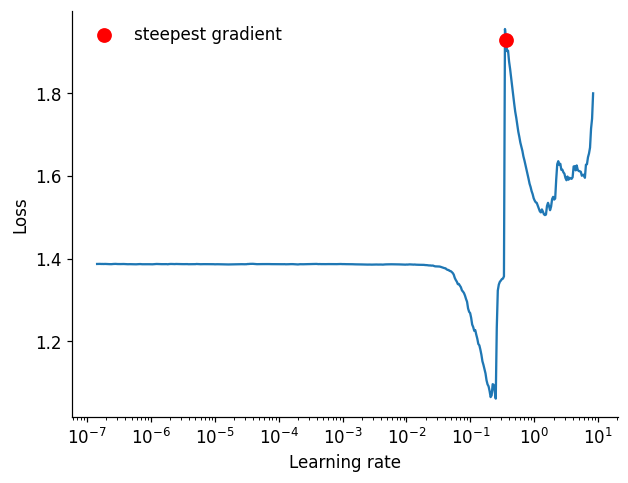

In [24]:
# `intent: learning-rate sweep and chosen schedule, with the plot that justifies it` -> T6 extra (range test, Smith 2017) + T6 (ReduceLROnPlateau)
# `note: run on cluster fold 0's learning set only (fit0), never on validation or test symbols.`
import torch.optim as optim                                  # T5
if ON_COLAB:
    !pip install -q torch-lr-finder==0.2.2                   # T6 extra: not on Colab by default
import warnings                                              # only to hide a harmless display warning on import
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    from torch_lr_finder import LRFinder                     # T6 extra
torch.manual_seed(SEED)                                      # T16: same starting weights every run
model = Net().to(device)                                     # a fresh network just for the test
criterion = nn.CrossEntropyLoss(weight=class_weights(fit0).to(device))  # T5c
optimizer = optim.SGD(model.parameters(), lr=1e-7, momentum=0.9)  # T6 extra: start tiny; T5: SGD with momentum 0.9
lr_finder = LRFinder(model, optimizer, criterion, device=device)  # T6 extra
g = torch.Generator(); g.manual_seed(SEED)                   # T16
import contextlib, io                                        # only to silence the progress bar
with contextlib.redirect_stderr(io.StringIO()):              # the 500-step progress bar adds nothing to the notebook
    lr_finder.range_test(make_loader(fit0, True, g), end_lr=10, num_iter=500)  # T6 extra: raise the rate step by step, record the loss. 500 batches (~8 epochs):
                                                             # with the README's 100 the loss never left ln(4) = 1.386 (pure guessing) at any rate
ax, steepest_lr = lr_finder.plot()                           # T6 extra: loss against learning rate. Version 0.2.2 also returns the rate where the loss falls fastest
                                                             # (seen in the library's output, not in its README, so treated as a hint only)
ax.figure.savefig(os.path.join(RESULTS_DIR, 'lr_range_test.png'), dpi=200)      # keep it: this plot is the justification for LR below
lr_finder.reset()                                            # T6 extra: put the model and optimizer back as they were

LR = 0.05                                                    # `intent: read off results/lr_range_test.png (2026-10-06, Zee to confirm)`
# `note: reading the plot. Loss flat at ln(4) = 1.386 up to ~0.03 (rate too small to learn), falls steeply to its lowest point near 0.2,
#  then blows up past 0.3. 0.05 sits inside the steep fall, ~4x below the lowest point and ~6x below the blow-up (Smith: pick a rate where
#  the loss is still clearly falling, below the minimum). The library's 'steepest gradient' marker (~0.36) is NOT used: it lands on the
#  recovery straight after the blow-up, which is the network recovering from a crash, not learning.`


cnn cluster: loaded saved results.
cnn random: loaded saved results.


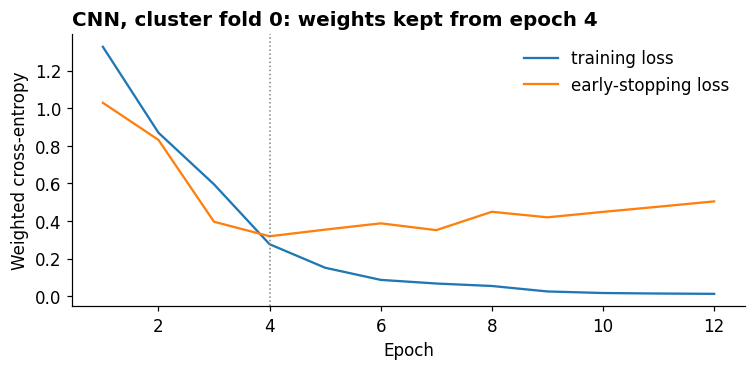

CNN, cluster split: macro F1 0.892 (folds 0.865 to 0.915)
CNN, random split: macro F1 0.923 (folds 0.901 to 0.940)


In [25]:
# `intent: train per fold with early stopping; save loss curves` -> T5 (training loop), T6 (ReduceLROnPlateau), T6b (early stopping, written ourselves), T11 (timing)
from torch.optim.lr_scheduler import ReduceLROnPlateau      # T6
MAX_EPOCHS = 60                                              # upper limit; early stopping normally ends training well before this
STOP_PATIENCE = 8                                            # T6b: epochs without a better early-stopping loss before training stops
LR_PATIENCE = 3                                              # T6: epochs without improvement before the rate is cut by 10x; shorter than STOP_PATIENCE so a cut gets a chance
QUICK = os.environ.get('BLISS_QUICK') == '1'                 # dev-box smoke test only: 1 fold, 2 epochs, to prove the code runs

def train_epoch(loader, model, loss_fn, optimizer):          # T5: one pass over the training data
    model.train()                                            # training mode
    running_loss = 0.0                                       # T5
    for i, data in enumerate(loader, 0):                     # T5
        inputs, targets = data                               # T5: get the inputs; data is a list of [inputs, labels]
        inputs, targets = inputs.to(device), targets.to(device)  # T15: move the batch to the GPU if there is one
        optimizer.zero_grad()                                # T5: zero the parameter gradients
        outputs = model(inputs)                              # T5: forward
        loss = loss_fn(outputs, targets)                     # T5
        loss.backward()                                      # T5: backward
        optimizer.step()                                     # T5: optimize
        running_loss += loss.item()                          # T5
    return running_loss / len(loader)                        # average training loss this epoch

def stop_loss(loader, model, loss_fn):                       # T6b: the T15 test() function, returning the loss instead of printing it
    num_batches = len(loader)                                # T15
    model.eval()                                             # T15
    test_loss = 0                                            # T15
    with torch.no_grad():                                    # T15: no gradients needed to measure
        for X, yb in loader:                                 # T15
            X, yb = X.to(device), yb.to(device)              # T15
            pred = model(X)                                  # T15
            test_loss += loss_fn(pred, yb).item()            # T15
    return test_loss / num_batches                           # T15: average loss

def predict(idx, model, channels=1, align='centre'):                         # class predictions for a set of symbols
    model.eval()
    out = []
    with torch.no_grad():
        for X, _ in make_loader(idx, False, channels=channels, align=align):  # fixed order, no shuffling
            out.append(model(X.to(device)).argmax(1).cpu().numpy())  # highest score = predicted class
    return np.concatenate(out)

def train_net(make_model, lr, channels, fit_idx, stop_idx, max_epochs, ckpt, weight_power=1.0, align='centre'):
    torch.manual_seed(SEED)                                  # T16: same starting weights in every fold
    g = torch.Generator(); g.manual_seed(SEED)               # T16: one shuffle stream per run, so each epoch gets a new order
    model = make_model().to(device)                          # T5 + T15: a fresh network (our CNN or ResNet18)
    loss_fn = nn.CrossEntropyLoss(weight=class_weights(fit_idx, weight_power).to(device))  # T5c
    optimizer = optim.SGD(model.parameters(), lr=lr, momentum=0.9)  # T5 / T13: SGD with momentum, at this model's starting rate
    scheduler = ReduceLROnPlateau(optimizer, "min", patience=LR_PATIENCE)  # T6
    best, wait, curve = np.inf, 0, []                        # T6b: best early-stopping loss so far, epochs since, loss history
    for epoch in range(max_epochs):                          # T5
        train_l = train_epoch(make_loader(fit_idx, True, g, channels, align), model, loss_fn, optimizer)  # T5
        stop_l = stop_loss(make_loader(stop_idx, False, channels=channels, align=align), model, loss_fn)  # T6b
        scheduler.step(stop_l)                               # T6: Note that step should be called after validate()
        curve.append((train_l, stop_l))                      # for the loss-curve plot
        if stop_l < best:                                    # T6b (original applied work): improved, so keep these weights
            best, wait = stop_l, 0
            torch.save(model.state_dict(), ckpt)             # T15 "Saving Models"
        else:                                                # T6b (original applied work): no improvement this epoch
            wait += 1
            if wait >= STOP_PATIENCE:                        # T6b: "Number of events to wait if no improvement and then stop the training"
                break
    model.load_state_dict(torch.load(ckpt, weights_only=True))  # T15 "Loading Models": go back to the best epoch
    return model, curve


def run_torch_model(name, make_model, lr, channels, rerun=False, weight_power=1.0, align='centre'):
    """Cross-validate on both splits, then train a final model on the whole dev set. Resumable: finished parts are loaded."""
    saved_path = os.path.join(RESULTS_DIR, f'{name}_results.pkl')  # one file per model, on Drive when on Colab
    if os.path.exists(saved_path) and not rerun:
        results.update(pickle.load(open(saved_path, 'rb')))  # load whatever is already done
    ckpt = os.path.join(RESULTS_DIR, f'{name}_best.pth')     # T6b: best weights so far in the current run
    for split_name, folds in [('cluster', cv_cluster), ('random', cv_random)]:  # the same folds the SVM used
        if (name, split_name) in results and not QUICK:
            print(f'{name} {split_name}: loaded saved results.'); continue
        oof = np.full(len(y), -1)                            # out-of-fold predictions; -1 = test set
        rec = {'fold_f1': [], 'fit_s': [], 'predict_s': [], 'epochs': [], 'curves': [], 'size_mb': []}
        for k, (tr, va) in enumerate(folds[:1] if QUICK else folds):
            fit_idx, stop_idx = early_stop_split(tr, split_name)  # T6b: early-stopping slice from the training fold
            t0 = time.perf_counter()
            model, curve = train_net(make_model, lr, channels, fit_idx, stop_idx, 2 if QUICK else MAX_EPOCHS, ckpt, weight_power, align)
            rec['fit_s'].append(time.perf_counter() - t0)    # training cost
            t0 = time.perf_counter()
            oof[va] = predict(va, model, channels, align)    # score on the fold it never saw
            rec['predict_s'].append(time.perf_counter() - t0)  # inference cost
            rec['fold_f1'].append(f1_score(y[va], oof[va], average='macro'))
            rec['epochs'].append(len(curve)); rec['curves'].append(curve)
            rec['size_mb'].append(os.path.getsize(ckpt) / 1e6)  # saved weights on disk
            print(f"{name} {split_name} fold {k}: macro F1 {rec['fold_f1'][-1]:.3f}, {len(curve)} epochs, {rec['fit_s'][-1]:.0f} s", flush=True)
        rec['oof'] = oof
        results[(name, split_name)] = rec
        if not QUICK:
            pickle.dump({k: v for k, v in results.items() if k[0] == name}, open(saved_path, 'wb'))  # save after each split
    if (name, 'final') not in results or QUICK:              # `intent: final model on the WHOLE dev set, predicts the held-out test set once`
        fit_idx, stop_idx = early_stop_split(dev_idx, 'cluster')  # early-stopping slice from the dev set, grouped
        t0 = time.perf_counter()
        model, curve = train_net(make_model, lr, channels, fit_idx, stop_idx, 2 if QUICK else MAX_EPOCHS, ckpt, weight_power, align)
        fit_s = time.perf_counter() - t0
        t0 = time.perf_counter()
        test_pred = predict(test_idx, model, channels, align)  # saved, NOT scored here; section 8 scores it
        results[(name, 'final')] = {'test_pred': test_pred, 'fit_s': fit_s, 'predict_s': time.perf_counter() - t0,
                                    'epochs': len(curve), 'curve': curve, 'size_mb': os.path.getsize(ckpt) / 1e6}
        torch.save(model.state_dict(), os.path.join(RESULTS_DIR, f'{name}_final.pth'))  # T15: the model itself, for Grad-CAM and LIME
        print(f'{name} final model trained on the dev set ({len(curve)} epochs, {fit_s:.0f} s). Test predictions saved, not scored.')
        if not QUICK:
            pickle.dump({k: v for k, v in results.items() if k[0] == name}, open(saved_path, 'wb'))

def show_curve_and_scores(name, title):
    curve = np.array(results[(name, 'cluster')]['curves'][0])  # loss curve of cluster fold 0
    fig, ax = plt.subplots(figsize=(7, 3.5))
    ax.plot(range(1, len(curve) + 1), curve[:, 0], label='training loss')
    ax.plot(range(1, len(curve) + 1), curve[:, 1], label='early-stopping loss')
    best_epoch = int(curve[:, 1].argmin()) + 1               # the epoch whose weights were kept
    ax.axvline(best_epoch, color='grey', linestyle=':', linewidth=1)
    ax.set_xlabel('Epoch'); ax.set_ylabel('Weighted cross-entropy')
    ax.set_title(f'{title}, cluster fold 0: weights kept from epoch {best_epoch}', loc='left')
    ax.legend(frameon=False)
    for side in ['top', 'right']:
        ax.spines[side].set_visible(False)
    fig.tight_layout(); fig.savefig(os.path.join(RESULTS_DIR, f'{name}_loss_curve.png'), dpi=200); plt.show()
    for split_name in ['cluster', 'random']:
        f = np.array(results[(name, split_name)]['fold_f1'])
        print(f'{title}, {split_name} split: macro F1 {f.mean():.3f} (folds {f.min():.3f} to {f.max():.3f})')

run_torch_model('cnn', Net, LR, channels=1)                  # our small CNN, LR from the range test (section above)
show_curve_and_scores('cnn', 'CNN')


## 7a-2. Small CNN with softened class weights (pre-declared fix, 2026-10-07)

**Written before running.** Sections 8 to 10 showed the small CNN over-calls BLUE: 317 YELLOW symbols called BLUE, BLUE precision 0.573
(cluster split). Likely cause: the 'balanced' class weights make a BLUE mistake cost about 8x a YELLOW one (2.82 vs 0.35), so the network
learns to say BLUE too readily. The SVM uses the same weights but under-calls BLUE, so the weights alone are not the whole story; this tests them.

- **One change only:** each class weight is square-rooted (power 0.5). BLUE vs YELLOW goes from ~8x to ~2.8x. Network, learning rate (0.05),
  folds, early stopping and seed are unchanged.
- **Success, decided now:** cluster-split macro F1 above the original CNN's 0.892, with the symbol-level paired test calling the gain real; and
  BLUE precision above 0.573 without BLUE recall falling below 0.80.
- **Counted as a 5th model** in every comparison, whatever the result.
- `note: square-root class weighting needs a source (Zee to source; e.g. Cui et al. 2019, "Class-Balanced Loss Based on Effective Number of Samples", discusses re-weighting strengths). Until then: original applied choice.`

*Source added 2026-10-09, after the run: Cui et al. (2019) note that re-weighting by "a smoothed version of inverse square root of class frequency" is often adopted. Square-rooting the 'balanced' weights gives exactly one over the square root of each class count, times a constant, with no clipping.*

Weights now: {'YELLOW': 0.5899999737739563, 'RED': 1.4800000190734863, 'BLUE': 1.6799999475479126, 'GREEN': 1.6699999570846558} (were {'YELLOW': 0.3499999940395355, 'RED': 2.180000066757202, 'BLUE': 2.819999933242798, 'GREEN': 2.7899999618530273} )
cnn_soft cluster: loaded saved results.
cnn_soft random: loaded saved results.


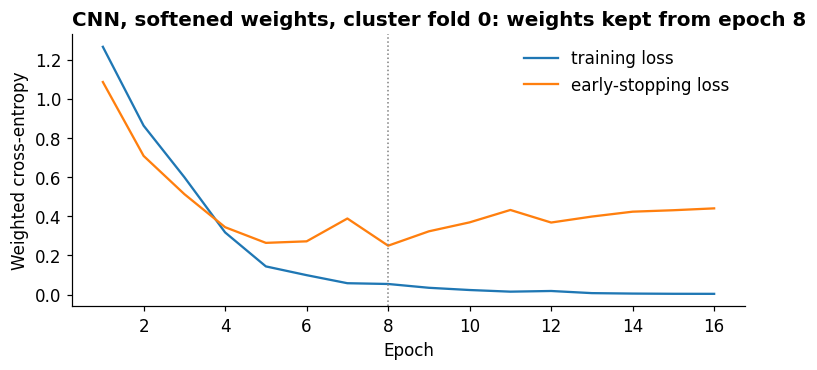

CNN, softened weights, cluster split: macro F1 0.917 (folds 0.909 to 0.933)
CNN, softened weights, random split: macro F1 0.922 (folds 0.892 to 0.950)


In [26]:
# `intent: the pre-declared fix: same CNN, class weights square-rooted` -> T5c (weight=), section 7a-2 above
print('Weights now:', dict(zip(CLASSES, class_weights(fit0, 0.5).round(decimals=2).tolist())), '(were', dict(zip(CLASSES, class_weights(fit0).round(decimals=2).tolist())), ')')
run_torch_model('cnn_soft', Net, LR, channels=1, weight_power=0.5)
show_curve_and_scores('cnn_soft', 'CNN, softened weights')

## 7a-3. Left-aligned input for the deep models (pre-declared, 2026-10-08)

**Written before running.** Left-aligning the drawings lifted HOG + SVM from 0.928 to 0.961 (section 6c), because HOG describes fixed
8 x 8 patches and centring put each symbol's first character and indicator in width-dependent patches. Only HOG got that input, so the
same change is now tried on the two deep models (softened weights), each counted as one more model.

- **One change:** left-aligned drawings (T1c). Everything else as 7a-2 (small CNN) and 7b-2 (ResNet18).
- **Prediction:** much smaller gains than HOG's 0.032. A convolution slides the same filter across the whole image, so the deep models
  already cope with shapes moving sideways.
- **Success:** cluster macro F1 above the centred version's (CNN 0.917, ResNet18 0.970) with the symbol-level paired test past the Bonferroni line.
- `note: both are trained on Colab's GPU; the centred CNN (7a-2) was trained on the dev-box CPU. GPU and CPU arithmetic differ very slightly,
  so the CNN comparison is not purely the alignment. The effect is tiny next to the differences being tested.`

cnn_left cluster: loaded saved results.
cnn_left random: loaded saved results.


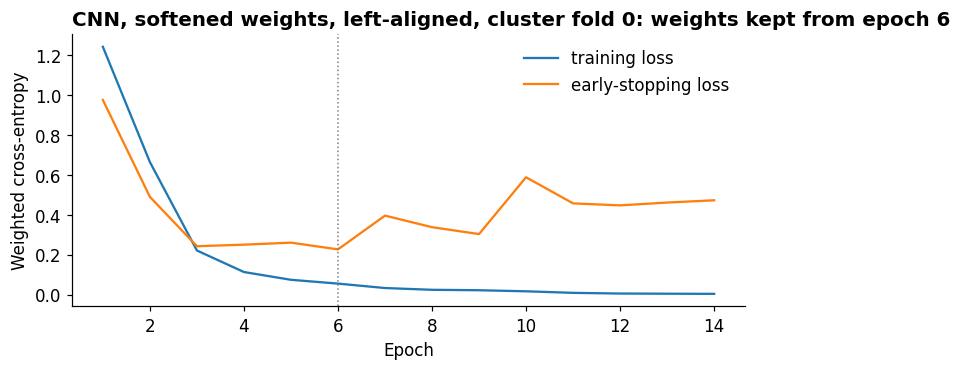

CNN, softened weights, left-aligned, cluster split: macro F1 0.941 (folds 0.925 to 0.949)
CNN, softened weights, left-aligned, random split: macro F1 0.951 (folds 0.937 to 0.969)


In [27]:
# `intent: small CNN, softened weights, LEFT-aligned input` -> T5, T1c; prediction written in 7a-3 before running
X_img_left = (1.0 - images_left.astype(np.float32) / 255.0)[:, None, :, :]  # same fixed scaling as X_img, from the left-aligned drawings (section 6c)
run_torch_model('cnn_left', Net, LR, channels=1, weight_power=0.5, align='left')
show_curve_and_scores('cnn_left', 'CNN, softened weights, left-aligned')

## 7b. Pretrained ResNet18

ResNet18 has 11 million parameters and was pretrained on ImageNet, 1.2 million everyday photos. My question was whether knowledge borrowed from photos helps with line drawings. It never saw a Bliss symbol before this, and it never saw my test set, so its score is a fair one. It does start with a head start, though, and I say that plainly.

There was a good reason to doubt it would help. Singer et al. (2022) found that an ImageNet-trained network scored 0.79 on photos but only 0.14 on drawings, and that fine-tuning on drawings brought it back to 0.79. Wang et al. (2019) built ImageNet-Sketch for the same reason: to measure how models trained on photos cope with drawings. So I tested both routes: ResNet18 fine-tuned here, and its frozen features with an SVM on top (section 7c).

Everything else matches the small CNN: same folds, class weights, early stopping and schedule. The grey image is copied into three identical channels because ResNet18 expects colour. The starting rate (0.001) is the PyTorch fine-tuning tutorial's, and every layer is fine-tuned. This needed a GPU, so it ran on a Colab T4.

resnet cluster: loaded saved results.
resnet random: loaded saved results.


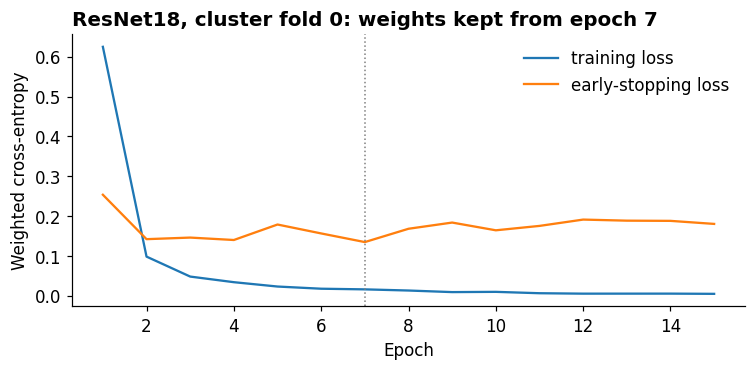

ResNet18, cluster split: macro F1 0.968 (folds 0.954 to 0.976)
ResNet18, random split: macro F1 0.972 (folds 0.965 to 0.981)


In [28]:
# `intent: fine-tune ResNet18, grey image copied to 3 channels, same folds` -> T13 + T17 (required, Nouh approved 3 models)
# `note: same trainer, folds, class weights, early stopping and schedule as the CNN, so only the network differs. Starting rate 0.001 is the
#  tutorial's fine-tuning rate (T13); the tutorial's StepLR is replaced by ReduceLROnPlateau so both deep models are scheduled the same way.
#  Input keeps our ink = 1 scaling; the tutorial's ImageNet mean/std normalisation is not applied (not in the transcribed snippet).`
# `note: GPU needed. On the dev box CPU this takes many hours; on a Colab T4 it should be roughly an hour.`
from torchvision import models                               # T13
def make_resnet():
    model_ft = models.resnet18(weights='IMAGENET1K_V1')      # T13: pretrained on ImageNet photos
    num_ftrs = model_ft.fc.in_features                       # T13
    model_ft.fc = nn.Linear(num_ftrs, len(CLASSES))          # T13: "generalized to nn.Linear(num_ftrs, len(class_names))", 4 classes
    return model_ft                                          # all parameters are trained (T13: "all parameters are being optimized")
RESNET_LR = 0.001                                            # T13: optim.SGD(..., lr=0.001, momentum=0.9)
run_torch_model('resnet', make_resnet, RESNET_LR, channels=3)
show_curve_and_scores('resnet', 'ResNet18')


## 7b-2. ResNet18 with softened class weights (pre-declared in section 6b)
Same trainer, folds, learning rate and schedule as 7b; only the class weights are square-rooted. GPU needed (Colab).

resnet_soft cluster: loaded saved results.
resnet_soft random: loaded saved results.


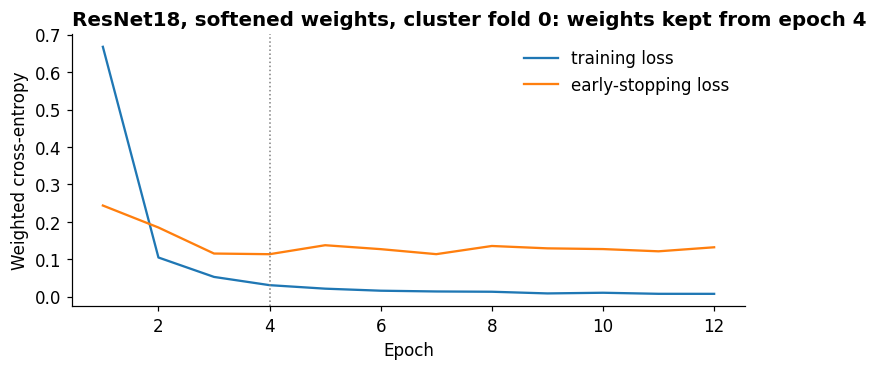

ResNet18, softened weights, cluster split: macro F1 0.970 (folds 0.965 to 0.975)
ResNet18, softened weights, random split: macro F1 0.974 (folds 0.965 to 0.980)


In [29]:
# `intent: ResNet18 with square-rooted class weights` -> T13, T5c; predictions written in section 6b before running
run_torch_model('resnet_soft', make_resnet, RESNET_LR, channels=3, weight_power=0.5)
show_curve_and_scores('resnet_soft', 'ResNet18, softened weights')

## 7b-3. ResNet18, softened weights, left-aligned (pre-declared in section 7a-3)
GPU needed (Colab).

resnet_left cluster: loaded saved results.
resnet_left random: loaded saved results.


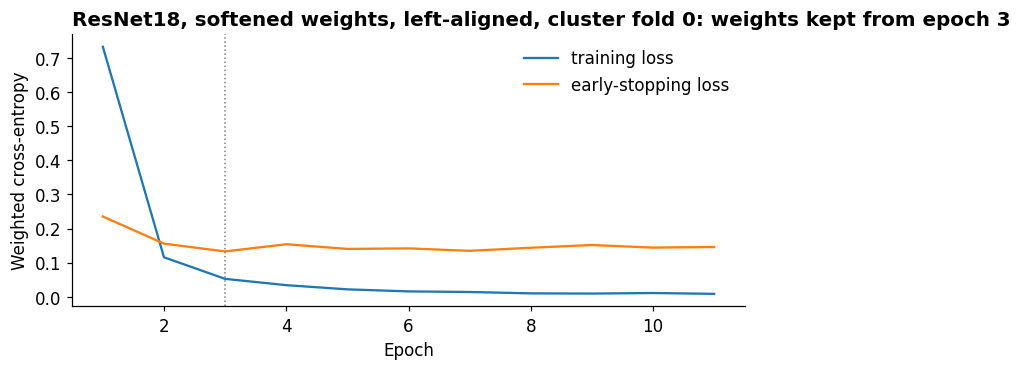

ResNet18, softened weights, left-aligned, cluster split: macro F1 0.971 (folds 0.961 to 0.978)
ResNet18, softened weights, left-aligned, random split: macro F1 0.973 (folds 0.969 to 0.978)


In [30]:
# `intent: ResNet18, softened weights, LEFT-aligned input` -> T13, T17, T1c; prediction written in 7a-3 before running
run_torch_model('resnet_left', make_resnet, RESNET_LR, channels=3, weight_power=0.5, align='left')
show_curve_and_scores('resnet_left', 'ResNet18, softened weights, left-aligned')

## 7c. Hybrid: frozen ResNet18 features + SVM (T19)

Takes the good part of each model: ResNet18's pretrained "eyes", used as they come (no fine-tuning, no GPU), and the SVM's cheap,
easy-to-tune classifier on top. HOG and fine-tuning are dropped. Razavian et al. (2014) showed this "off-the-shelf" recipe is a strong baseline.
**Question:** is ResNet18's win down to its pretrained features, or to fine-tuning them?

In [31]:
# `intent: 512 pretrained ResNet18 features per symbol (frozen), then the same nested SVM search and folds as HOG + SVM` -> T19, T13, T17, T3/T3b
from torchvision.models.feature_extraction import create_feature_extractor  # T19
HYBRID_SAVED = os.path.join(RESULTS_DIR, 'hybrid_results.pkl')
backbone = models.resnet18(weights='IMAGENET1K_V1')         # T13: the ImageNet weights, exactly as loaded before fine-tuning
backbone = create_feature_extractor(backbone, {'avgpool': 'feat'})  # T19: stop at the last pooling layer, before the classifier
backbone = backbone.to(device).eval()                        # inference only: the weights are never trained
t0 = time.perf_counter()
feats = []
with torch.no_grad():                                        # frozen: no gradients
    for X, _ in make_loader(np.arange(len(y)), False, channels=3):  # T17: every symbol as a 3-channel image, fixed order
        feats.append(torch.flatten(backbone(X.to(device))['feat'], 1).cpu().numpy())  # T19 output 512 x 1 x 1 -> 512 numbers
X_res = np.concatenate(feats)                                # (6015, 512)
feature_seconds = time.perf_counter() - t0
print(f'ResNet18 features: {X_res.shape} in {feature_seconds:.0f} s on {device}')
# `note: like HOG, a fixed recipe with nothing fitted to our data, so computing it once for every symbol leaks nothing.`

HYBRID_GRID = {'svc__C': [10, 100, 1000], 'svc__gamma': [1e-4, 1e-3, 1e-2]}  # C widened 2026-10-07: first run (C 1 to 100) put 100 on the top edge in 5 of 10 folds; C = 1 never won  # sklearn's 'scale' is ~1/512 = 2e-3 for 512 standardised features; the grid brackets it
# `note: Razavian et al. used a LINEAR SVM. We keep the RBF SVM so the only change from HOG + SVM is the features.`
saved = pickle.load(open(HYBRID_SAVED, 'rb')) if os.path.exists(HYBRID_SAVED) else {}
results.update(saved)
for split_name, folds in [('cluster', cv_cluster), ('random', cv_random)]:
    if ('hybrid', split_name) in results:
        print(f'hybrid {split_name}: loaded saved results.'); continue
    oof = np.full(len(y), -1)
    rec = {'fold_f1': [], 'fit_s': [], 'predict_s': [], 'best': [], 'size_mb': []}
    for k, (tr, va) in enumerate(folds):
        search = make_svm_search(split_name, HYBRID_GRID)    # same pipeline, class weights and inner folds as HOG + SVM (T3, T3b)
        fit_groups = {'groups': groups[tr]} if split_name == 'cluster' else {}
        t0 = time.perf_counter(); search.fit(X_res[tr], y[tr], **fit_groups); rec['fit_s'].append(time.perf_counter() - t0)
        t0 = time.perf_counter(); oof[va] = search.predict(X_res[va]); rec['predict_s'].append(time.perf_counter() - t0)
        rec['fold_f1'].append(f1_score(y[va], oof[va], average='macro'))
        rec['best'].append(search.best_params_)
        rec['size_mb'].append(len(pickle.dumps(search.best_estimator_)) / 1e6)
        print(f"hybrid {split_name} fold {k}: macro F1 {rec['fold_f1'][-1]:.3f}, best {search.best_params_}, {rec['fit_s'][-1]:.0f} s", flush=True)
    rec['oof'] = oof
    results[('hybrid', split_name)] = rec
    pickle.dump({k: v for k, v in results.items() if k[0] == 'hybrid'}, open(HYBRID_SAVED, 'wb'))
if ('hybrid', 'final') not in results:                       # final model on the whole dev set; test predictions saved, not scored
    search = make_svm_search('cluster', HYBRID_GRID)
    t0 = time.perf_counter(); search.fit(X_res[dev_idx], y[dev_idx], groups=groups[dev_idx]); fit_s = time.perf_counter() - t0
    t0 = time.perf_counter(); test_pred = search.predict(X_res[test_idx])
    results[('hybrid', 'final')] = {'test_pred': test_pred, 'best': search.best_params_, 'fit_s': fit_s,
                                    'predict_s': time.perf_counter() - t0, 'size_mb': len(pickle.dumps(search.best_estimator_)) / 1e6}
    pickle.dump(search.best_estimator_, open(os.path.join(RESULTS_DIR, 'hybrid_final.pkl'), 'wb'))
    pickle.dump({k: v for k, v in results.items() if k[0] == 'hybrid'}, open(HYBRID_SAVED, 'wb'))
    print(f"Final hybrid trained on the dev set, best {search.best_params_}. Test predictions saved, not scored.")
for split_name in ['cluster', 'random']:
    rec = results[('hybrid', split_name)]
    edge = [b for b in rec['best'] if b['svc__C'] == 1000 or b['svc__gamma'] in (1e-4, 1e-2)]  # C = 10 is not an edge: C = 1 was tested and never won
    if edge:
        print(f'WARNING ({split_name}): {len(edge)} of 5 folds picked a value on the edge of the grid.')
    f = np.array(rec['fold_f1'])
    print(f'Hybrid, {split_name} split: macro F1 {f.mean():.3f} (folds {f.min():.3f} to {f.max():.3f})')

ResNet18 features: (6015, 512) in 40 s on cpu
hybrid cluster: loaded saved results.
hybrid random: loaded saved results.
WARNING (cluster): 1 of 5 folds picked a value on the edge of the grid.
Hybrid, cluster split: macro F1 0.880 (folds 0.862 to 0.902)
WARNING (random): 1 of 5 folds picked a value on the edge of the grid.
Hybrid, random split: macro F1 0.896 (folds 0.885 to 0.907)


## 8. Evaluation and comparison

Models compared: ['HOG + SVM', 'Small CNN', 'ResNet18 (pretrained)', 'ResNet18 features + SVM', 'Small CNN, softened weights', 'HOG + SVM, softened weights', 'ResNet18, softened weights', 'HOG + SVM, left-aligned (softened weights)', 'Small CNN, left-aligned (softened weights)', 'ResNet18, left-aligned (softened weights)']
Always answering YELLOW would score accuracy 0.708 but macro F1 0.207, which is why macro F1 is the main score.

=== HOG + SVM, cluster split, all 5,413 dev symbols ===
              precision    recall  f1-score   support

      YELLOW      0.962     0.976     0.969      3830
         RED      0.964     0.958     0.961       619
        BLUE      0.828     0.764     0.795       479
       GREEN      0.977     0.951     0.963       485

    accuracy                          0.953      5413
   macro avg      0.933     0.912     0.922      5413
weighted avg      0.952     0.953     0.952      5413

=== Small CNN, cluster split, all 5,413 dev symbols ===
              p

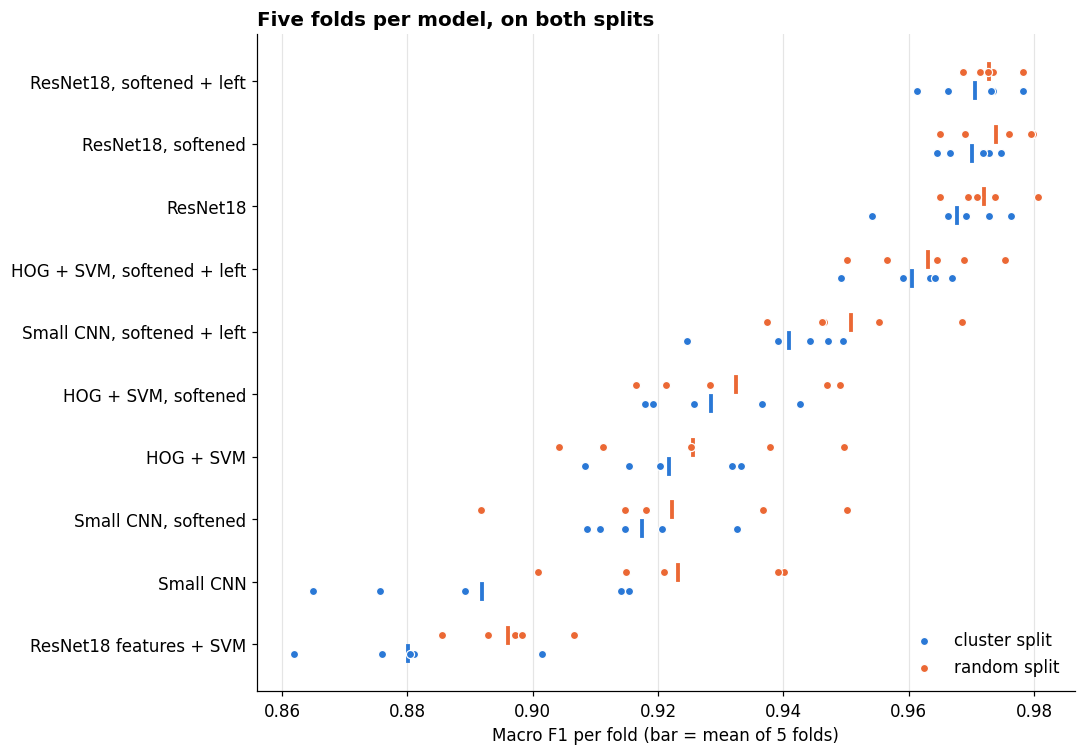

,model,split,macro F1,F1 sd,F1 worst fold,F1 best fold,accuracy
0,HOG + SVM,cluster,0.922,0.011,0.908,0.933,0.953
1,HOG + SVM,random,0.926,0.019,0.904,0.950,0.955
2,Small CNN,cluster,0.892,0.023,0.865,0.915,0.919
3,Small CNN,random,0.923,0.017,0.901,0.940,0.948
4,ResNet18 (pretrained),cluster,0.968,0.008,0.954,0.976,0.979
5,ResNet18 (pretrained),random,0.972,0.006,0.965,0.981,0.982
6,ResNet18 features + SVM,cluster,0.880,0.014,0.862,0.902,0.927
7,ResNet18 features + SVM,random,0.896,0.008,0.885,0.907,0.938
8,"Small CNN, softened weights",cluster,0.917,0.010,0.909,0.933,0.947
9,"Small CNN, softened weights",random,0.922,0.022,0.892,0.950,0.949


In [32]:
# `intent: macro precision/recall/F1 + accuracy per model, mean ± spread across folds` -> T7
# `note: everything in this section uses the out-of-fold predictions on the 5,413 dev symbols. The held-out test set is scored separately, once, in 8b.`
from sklearn.metrics import classification_report           # T7
ALL_MODELS = [('svm', 'HOG + SVM'), ('cnn', 'Small CNN'), ('resnet', 'ResNet18 (pretrained)'), ('hybrid', 'ResNet18 features + SVM'),
              ('cnn_soft', 'Small CNN, softened weights'), ('svm_soft', 'HOG + SVM, softened weights'), ('resnet_soft', 'ResNet18, softened weights'),
              ('svm_left', 'HOG + SVM, left-aligned (softened weights)'), ('cnn_left', 'Small CNN, left-aligned (softened weights)'),
              ('resnet_left', 'ResNet18, left-aligned (softened weights)')]
MODELS = [m for m in ALL_MODELS if (m[0], 'cluster') in results]  # only models whose results are present on this machine
print('Models compared:', [t for _, t in MODELS])  # fixed order for every table and chart
FOLDS = {'cluster': cv_cluster, 'random': cv_random}
rows = []
for key, title in MODELS:
    for split_name, folds in FOLDS.items():
        rec = results[(key, split_name)]
        f = np.array(rec['fold_f1'])                         # macro F1 per fold
        acc = np.array([np.mean(rec['oof'][va] == y[va]) for _, va in folds])  # accuracy per fold
        rows.append({'model': title, 'split': split_name, 'macro F1': round(f.mean(), 3), 'F1 sd': round(f.std(ddof=1), 3),
                     'F1 worst fold': round(f.min(), 3), 'F1 best fold': round(f.max(), 3), 'accuracy': round(acc.mean(), 3)})
summary = pd.DataFrame(rows)                                 # one row per model and split
print('Always answering YELLOW would score accuracy 0.708 but macro F1 0.207, which is why macro F1 is the main score.\n')
for key, title in MODELS:                                    # T7: full per-class report, cluster split (the honest one)
    oof = results[(key, 'cluster')]['oof']
    print(f'=== {title}, cluster split, all 5,413 dev symbols ===')
    print(classification_report(y[dev_idx], oof[dev_idx], target_names=CLASSES, digits=3))  # T7: precision, recall, F1 per class + macro avg

SHORT = {'svm': 'HOG + SVM', 'cnn': 'Small CNN', 'resnet': 'ResNet18', 'hybrid': 'ResNet18 features + SVM',
         'cnn_soft': 'Small CNN, softened', 'svm_soft': 'HOG + SVM, softened', 'resnet_soft': 'ResNet18, softened',
         'svm_left': 'HOG + SVM, softened + left', 'cnn_left': 'Small CNN, softened + left', 'resnet_left': 'ResNet18, softened + left'}
order = sorted(MODELS, key=lambda m: np.mean(results[(m[0], 'cluster')]['fold_f1']))  # weakest at the bottom
fig, ax = plt.subplots(figsize=(10, 0.55 * len(order) + 1.5))  # one row per model, so the names never overlap
colours = {'cluster': '#2a78d6', 'random': '#eb6834'}        # categorical slots 1 and 2 of the validated reference palette
for r, (key, title) in enumerate(order):
    for split_name, dy in [('cluster', -0.15), ('random', 0.15)]:
        f = results[(key, split_name)]['fold_f1']
        ax.scatter(f, [r + dy] * len(f), s=28, color=colours[split_name], edgecolor='white', linewidth=0.8, zorder=3,
                   label=f'{split_name} split' if r == 0 else None)
        ax.plot([np.mean(f)] * 2, [r + dy - 0.12, r + dy + 0.12], color=colours[split_name], linewidth=2.5)  # short bar = mean
ax.set_yticks(range(len(order)), [SHORT[k] for k, _ in order])
ax.set_xlabel('Macro F1 per fold (bar = mean of 5 folds)')
ax.set_title('Five folds per model, on both splits', loc='left')
ax.grid(axis='x', color='#e5e5e5', linewidth=0.8); ax.set_axisbelow(True)
ax.legend(loc='lower right')
fig.tight_layout(); fig.savefig(os.path.join(RESULTS_DIR, 'model_comparison.png'), dpi=200); plt.show()
summary

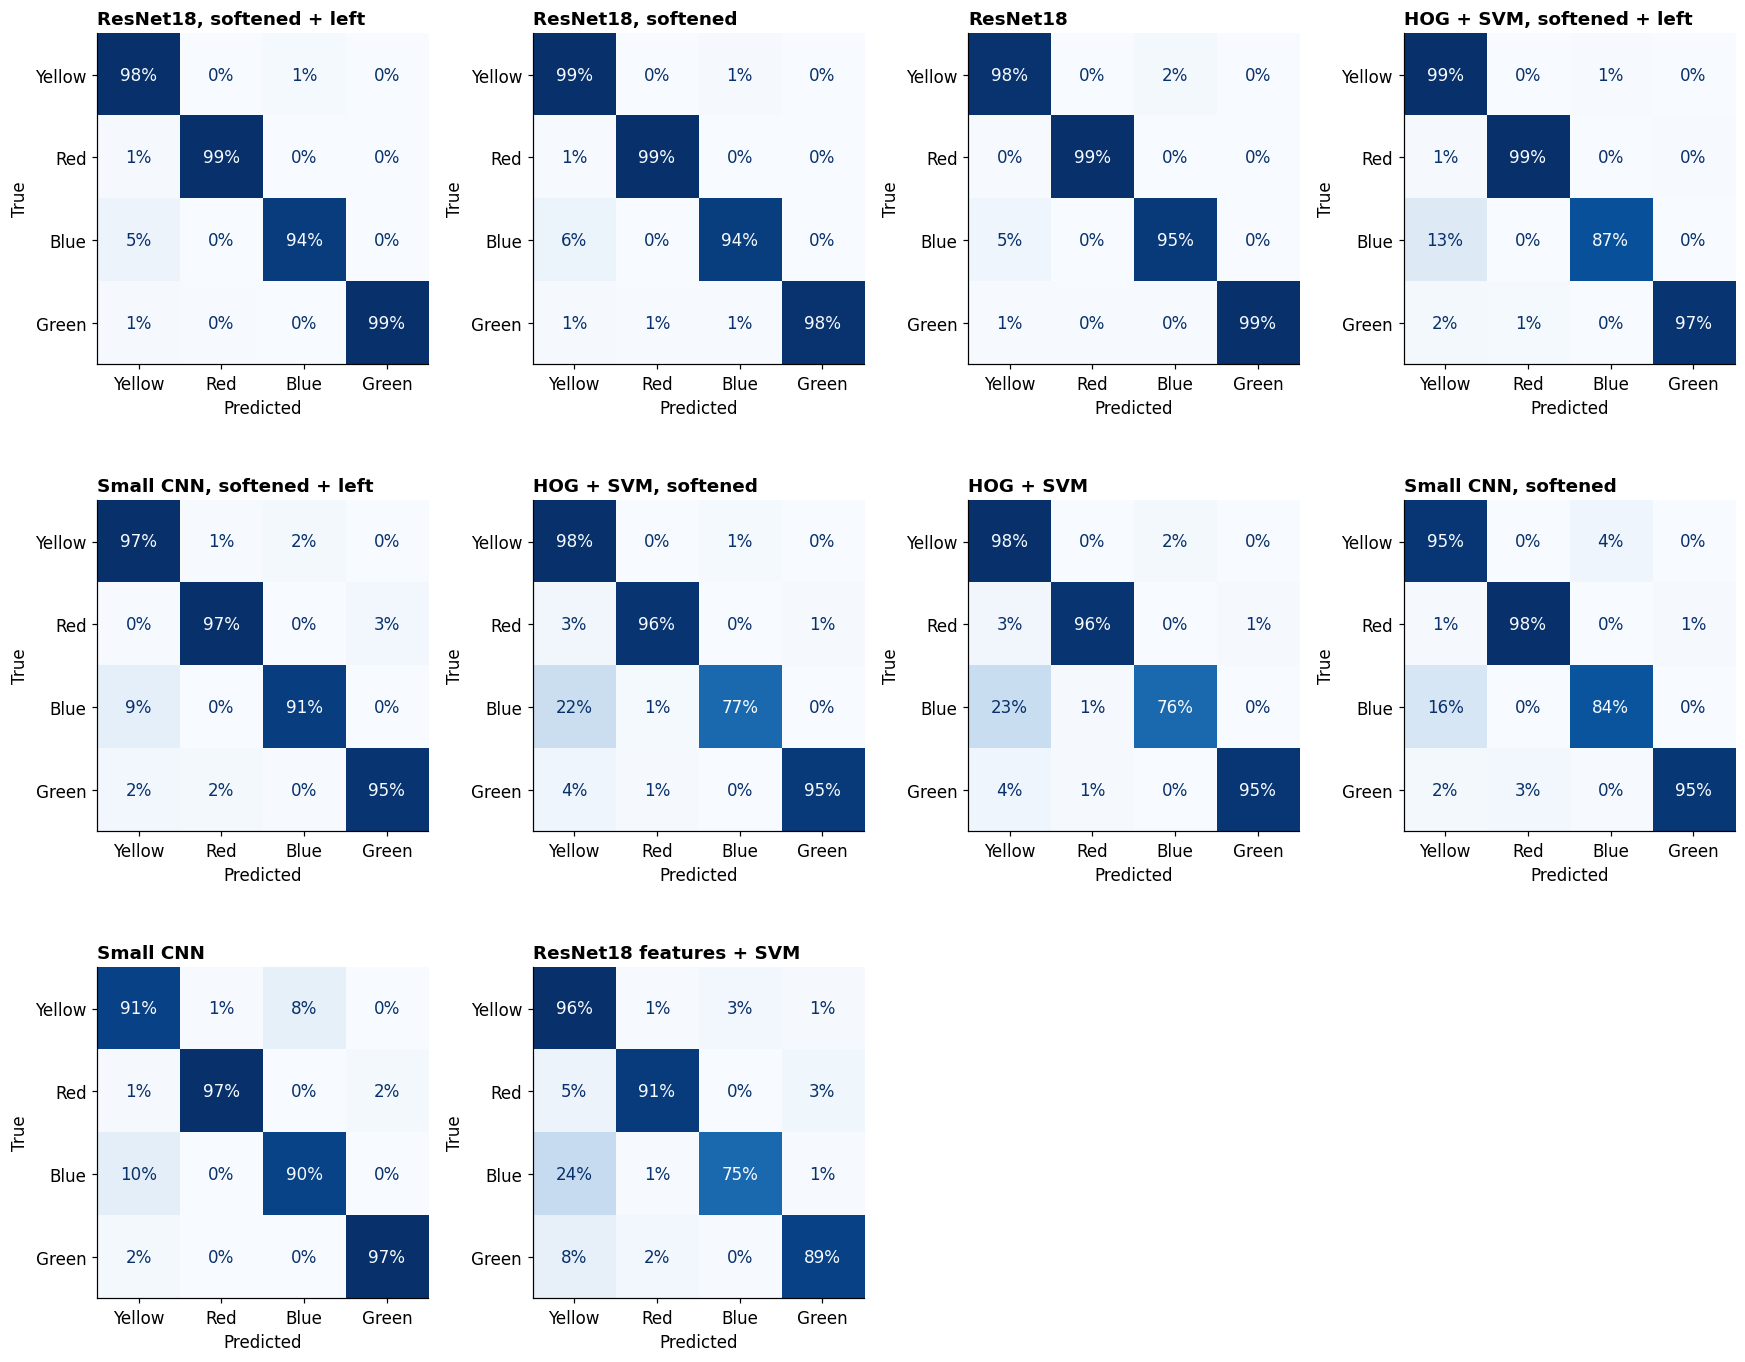

In [33]:
# `intent: confusion matrix per model` -> T7 extra (ConfusionMatrixDisplay), cluster split, all dev symbols
# `note: each row is normalised to 100% of that true class (confusion_matrix's normalize='true'), so the small classes are readable next to the 71% one.`
from sklearn import metrics                                  # T7 extra
ncol = 4                                                     # four panels per row
nrow = int(np.ceil(len(order) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(16, 4.3 * nrow))
for ax, (key, title) in zip(axes.flat, order[::-1]):         # strongest model first
    oof = results[(key, 'cluster')]['oof']
    confusion_matrix = metrics.confusion_matrix(y[dev_idx], oof[dev_idx], normalize='true')  # T7 extra: rows = true class, columns = predicted
    cm_display = metrics.ConfusionMatrixDisplay(confusion_matrix = confusion_matrix, display_labels = [c.title() for c in CLASSES])  # T7 extra
    cm_display.plot(ax=ax, colorbar=False, cmap='Blues', values_format='.0%')  # T7 extra; percentages, no colour bar
    ax.set_title(SHORT[key], loc='left', fontsize=12)
    ax.set_xlabel('Predicted'); ax.set_ylabel('True')
for ax in list(axes.flat)[len(order):]:                      # hide unused panels
    ax.axis('off')
fig.tight_layout(); fig.savefig(os.path.join(RESULTS_DIR, 'confusion_matrices.png'), dpi=200); plt.show()

In [34]:
# `intent: paired test on per-fold scores: is the gap bigger than fold noise?` -> T12 (permutation_test, permutation_type='samples')
# `note: TWO levels, because 5 folds alone cannot reach p < 0.05. With 5 paired folds there are only 2**5 = 32 ways to swap the
#  pairs, so the smallest possible two-sided p-value is 2/32 = 0.0625. The fold-level test is reported, but the decision rests on the
#  symbol-level test: each dev symbol has a prediction from both models, and swapping the two predictions symbol by symbol is the
#  same 'samples' permutation on 5,413 pairs: a paired approximate randomisation test (Yeh, 2000).`
# `note: a result counts at p < 0.05 / (number of comparisons) (Bonferroni; original applied choice). 22 comparisons when all 10 models are present -> 0.0023.`
from scipy.stats import permutation_test                     # T12
rng = np.random.default_rng(SEED)                            # T12: seeded, so the p-values rerun identically
def statistic(x, y_, axis):                                  # T12: difference in mean (x minus y)
    return np.mean(x, axis=axis) - np.mean(y_, axis=axis)
y_dev = y[dev_idx]                                           # true classes of the dev symbols, in a fixed order
def f1_gap(pa, pb):                                          # symbol-level statistic: macro F1 of predictions a minus b
    return f1_score(y_dev, pa, average='macro') - f1_score(y_dev, pb, average='macro')
comparisons = [(('resnet', 'cluster'), ('svm', 'cluster')),   # does pretrained deep beat classical?
               (('svm', 'cluster'), ('cnn', 'cluster')),      # does classical beat deep from scratch?
               (('resnet', 'cluster'), ('cnn', 'cluster')),   # does pretraining help deep learning?
               (('resnet', 'cluster'), ('hybrid', 'cluster')),  # T19: does fine-tuning add anything over frozen pretrained features?
               (('hybrid', 'cluster'), ('svm', 'cluster')),   # T19: do pretrained features beat HOG under the same SVM?
               (('cnn_soft', 'cluster'), ('cnn', 'cluster')),  # 7a-2: did softening the weights help the CNN?
               (('svm_soft', 'cluster'), ('svm', 'cluster')),  # 6b: ... the SVM?
               (('resnet_soft', 'cluster'), ('resnet', 'cluster')),  # 6b / 7b-2: ... ResNet18?
               (('svm_left', 'cluster'), ('svm_soft', 'cluster')),  # 6c: does left-aligning help HOG?
               (('cnn_left', 'cluster'), ('cnn_soft', 'cluster')),  # 7a-3: ... the small CNN?
               (('resnet_left', 'cluster'), ('resnet_soft', 'cluster'))]  # 7a-3: ... ResNet18?
comparisons = [(a, b) for a, b in comparisons if a in results and b in results]  # skip pairs whose results are missing here
comparisons += [((k, 'random'), (k, 'cluster')) for k, _ in MODELS]  # split gap for every model present  # does each model score higher when families are split?
HEADLINE_CV = (('resnet_soft', 'cluster'), ('svm_left', 'cluster'))  # the two headline models (section 8b): best deep vs best classical
if all(m in results for m in HEADLINE_CV):
    comparisons.append(HEADLINE_CV)                          # added last (2026-10-10), with its own seeded generator below, so every other p-value is unchanged
rows = []
for a, b in comparisons:
    rng_ = np.random.default_rng(SEED) if (a, b) == HEADLINE_CV else rng
    fa, fb = np.array(results[a]['fold_f1']), np.array(results[b]['fold_f1'])
    fold_p = np.nan
    if a[1] == b[1]:                                         # fold-level pairing only makes sense on the same folds
        fold_p = permutation_test((fa, fb), statistic, permutation_type='samples', vectorized=True,
                                  n_resamples=9999, alternative='two-sided', rng=rng_).pvalue  # T12 (all 32 swaps are enumerated)
    res = permutation_test((results[a]['oof'][dev_idx], results[b]['oof'][dev_idx]), f1_gap,
                           permutation_type='samples', vectorized=False, n_resamples=9999,
                           alternative='two-sided', rng=rng_)  # T12 'samples' on 5,413 symbol pairs
    rows.append({'A': f'{a[0]} ({a[1]})', 'B': f'{b[0]} ({b[1]})', 'F1 gap A-B': round(res.statistic, 3),
                 'p (5 folds)': None if np.isnan(fold_p) else round(fold_p, 4), 'p (5,413 symbols)': round(res.pvalue, 4),
                 'verdict': 'real difference' if res.pvalue < 0.05 / len(comparisons) else 'within noise'})
paired_tests = pd.DataFrame(rows)
paired_tests

,A,B,F1 gap A-B,p (5 folds),"p (5,413 symbols)",verdict
0,resnet (cluster),svm (cluster),0.045,0.0625,0.0002,real difference
1,svm (cluster),cnn (cluster),0.032,0.1250,0.0002,real difference
2,resnet (cluster),cnn (cluster),0.077,0.0625,0.0002,real difference
3,resnet (cluster),hybrid (cluster),0.087,0.0625,0.0002,real difference
4,hybrid (cluster),svm (cluster),-0.042,0.0625,0.0002,real difference
5,cnn_soft (cluster),cnn (cluster),0.027,0.1250,0.0002,real difference
6,svm_soft (cluster),svm (cluster),0.007,0.1250,0.0156,within noise
7,resnet_soft (cluster),resnet (cluster),0.003,0.6250,0.2056,within noise
8,svm_left (cluster),svm_soft (cluster),0.032,0.0625,0.0002,real difference
9,cnn_left (cluster),cnn_soft (cluster),0.023,0.0625,0.0002,real difference


In [35]:
# `intent: cost table: training time, inference time, model size vs F1` -> T11 (timing with time.perf_counter; the T11 profiler is PyTorch only)
# `note: the hardware differs and must be read with the numbers. Where the saved results were made:`
HARDWARE = {'svm': 'dev-box CPU, 12 cores (search on 4)', 'cnn': 'dev-box CPU, 12 cores', 'resnet': 'Colab T4 GPU',
            'hybrid': 'dev-box CPU, 12 cores (search on 4)', 'cnn_soft': 'dev-box CPU, 12 cores',
            'svm_soft': 'dev-box CPU, 12 cores (search on 4)', 'resnet_soft': 'Colab T4 GPU',
            'svm_left': 'dev-box CPU, 12 cores (search on 4)', 'cnn_left': 'Colab T4 GPU', 'resnet_left': 'Colab T4 GPU'}
TRAIN_INCLUDES = {'svm': '27-fit C/gamma search + refit', 'cnn': 'one run to early stop', 'resnet': 'one run to early stop',
                  'hybrid': '27-fit C/gamma search + refit (features extracted once, separately)', 'cnn_soft': 'one run to early stop',
                  'svm_soft': '27-fit C/gamma search + refit', 'resnet_soft': 'one run to early stop',
                  'svm_left': '27-fit C/gamma search + refit', 'cnn_left': 'one run to early stop', 'resnet_left': 'one run to early stop'}
rows = []
for key, title in MODELS:
    rec = results[(key, 'cluster')]
    per_symbol_ms = 1000 * np.sum(rec['predict_s']) / len(dev_idx)  # prediction time per symbol
    rows.append({'model': title, 'hardware': HARDWARE[key], 'train time per fold (min)': round(np.mean(rec['fit_s']) / 60, 1),
                 'training includes': TRAIN_INCLUDES[key], 'predict (ms per symbol)': round(per_symbol_ms, 2),
                 'model size (MB)': round(np.mean(rec['size_mb']), 1), 'macro F1 (cluster)': round(np.mean(rec['fold_f1']), 3)})
cost = pd.DataFrame(rows)
for key, f in [('svm', 'svm_final.pkl'), ('svm_left', 'svm_left_final.pkl')]:  # why the SVM is big and slow: it keeps training symbols
    path = os.path.join(RESULTS_DIR, f)
    if os.path.exists(path):
        n_sv = pickle.load(open(path, 'rb'))['svc'].n_support_.sum()  # T3: support vectors kept by the final model
        print(f'{dict(MODELS)[key]}: the final model keeps {n_sv:,} training symbols (support vectors) and compares every new symbol with each one.')
print('HOG features for all 6,015 symbols took', f'{hog_seconds:.0f} s' if 'hog_seconds' in globals() else 'see section 6', '(SVM only).')
cost

HOG + SVM: the final model keeps 2,049 training symbols (support vectors) and compares every new symbol with each one.
HOG + SVM, left-aligned (softened weights): the final model keeps 1,227 training symbols (support vectors) and compares every new symbol with each one.
HOG features for all 6,015 symbols took 16 s (SVM only).


,model,hardware,train time per fold (min),training includes,predict (ms per symbol),model size (MB),macro F1 (cluster)
0,HOG + SVM,"dev-box CPU, 12 cores (search on 4)",11.8,27-fit C/gamma search + refit,12.24,119.0,0.922
1,Small CNN,"dev-box CPU, 12 cores",1.3,one run to early stop,0.37,6.3,0.892
2,ResNet18 (pretrained),Colab T4 GPU,1.6,one run to early stop,0.81,44.8,0.968
3,ResNet18 features + SVM,"dev-box CPU, 12 cores (search on 4)",0.5,27-fit C/gamma search + refit (features extrac...,0.33,6.9,0.880
4,"Small CNN, softened weights","dev-box CPU, 12 cores",1.2,one run to early stop,0.34,6.3,0.917
5,"HOG + SVM, softened weights","dev-box CPU, 12 cores (search on 4)",9.2,27-fit C/gamma search + refit,7.88,120.0,0.928
6,"ResNet18, softened weights",Colab T4 GPU,1.4,one run to early stop,0.75,44.8,0.970
7,"HOG + SVM, left-aligned (softened weights)","dev-box CPU, 12 cores (search on 4)",4.7,27-fit C/gamma search + refit,4.77,69.1,0.961
8,"Small CNN, left-aligned (softened weights)",Colab T4 GPU,0.2,one run to early stop,0.07,6.3,0.941
9,"ResNet18, left-aligned (softened weights)",Colab T4 GPU,1.5,one run to early stop,0.84,44.8,0.971


### What the evaluation shows

**Ranking (cross-validation, family split).** ResNet18 0.968 to 0.971 across its versions. HOG + SVM, left-aligned 0.961. Small CNN, left-aligned 0.941. The original HOG + SVM 0.922, the original small CNN 0.892, and frozen ResNet18 features + SVM 0.880.

**Every pre-declared fix was judged against a rule written before it ran.**
- Softer class weights (square-rooted) lifted the small CNN by 0.027. Real (p < 0.0002). It was over-calling BLUE: a BLUE mistake had cost it 8 times a YELLOW one.
- The same change on the SVM (+0.007) and ResNet18 (+0.003) did not pass the significance line.
- Left-aligning the drawings lifted HOG + SVM by 0.032 and the small CNN by 0.023, both real. It did nothing for ResNet18. The reason is the last layer. The SVM and the small CNN give every position its own weight, so a shape in a different place looks like a different shape. ResNet18 averages each feature over the whole image before deciding, so where the drawing sits doesn't matter to it.

**The hybrid failed, and that's informative.** Frozen ImageNet features + an SVM scored 0.880, below plain HOG. So ResNet18 doesn't win because of its photo features. It wins because those features are fine-tuned on Bliss. That matches Singer et al. (2022), who found ImageNet features handle drawings badly until they are fine-tuned.

**Best deep vs best classical.** ResNet18 (softened) is ahead of the left-aligned SVM by 0.010 in cross-validation. With 22 comparisons my significance line is p < 0.0023, and this gap gets p = 0.0034 (the last row of the table). That's close, but by my own rule it's within noise, so I call it level.

**Cost.** HOG + SVM needs no GPU, but it's the slowest to use: about 4.8 ms per symbol on my laptop and 69 MB, because it compares every new symbol against 1,227 stored training symbols. ResNet18 takes about 0.8 ms per symbol on a GPU and is 45 MB. The small CNN is the lightest at 6 MB. The hardware differs between models, so these numbers show the shape of the trade-off, not exact speeds.

## 8b. Held-out test set (scored once)

The 602 symbols split off in section 5 have not been used for training, tuning, early stopping or any design choice.
Each model's final version (trained on all 5,413 dev symbols) predicted them once, and those predictions were saved unscored.

**Locked before unsealing (Zee, 2026-10-08).** Ten models, final. Two headline models, chosen on cross-validation alone:
- **Best deep model: ResNet18, softened weights, centred input** (CV 0.970). Left-aligning added nothing for it (0.971, p = 0.92), so the simpler input is kept.
- **Best classical model: HOG + SVM, left-aligned, softened weights** (CV 0.961).

All ten are scored below; the headline pair is fixed regardless of what the test shows.


In [36]:
# `intent: score the held-out test set ONCE, after every design choice is final` -> T7 (report), T12 (paired, symbol level)
UNSEAL_TEST = True                                           # unsealed 2026-10-08, after the ten models and the headline pair were locked
HEADLINE = [('resnet_soft', 'Best deep: ResNet18'), ('svm_left', 'Best classical: HOG + SVM, left-aligned')]
if not UNSEAL_TEST:
    print('Test set still sealed. Set UNSEAL_TEST = True once every model is final.')
else:
    y_test = y[test_idx]
    rows = []
    for key, title in MODELS:
        pred = results[(key, 'final')]['test_pred']          # saved by each model's final fit, never scored until now
        rows.append({'model': title, 'test macro F1': round(f1_score(y_test, pred, average='macro'), 3),
                     'CV macro F1 (cluster)': round(np.mean(results[(key, 'cluster')]['fold_f1']), 3),
                     'test accuracy': round(np.mean(pred == y_test), 3)})
        if key in dict(HEADLINE):                            # full per-class report for the two headline models only
            print(f'=== {title}, held-out test (602 symbols) ===')
            print(classification_report(y_test, pred, target_names=CLASSES, digits=3))  # T7
    test_scores = pd.DataFrame(rows).sort_values('test macro F1', ascending=False)
    display(test_scores)
    (a, _), (b, _) = HEADLINE                                 # T12 on the test set: is the headline gap bigger than noise?
    test_gap = permutation_test((results[(a, 'final')]['test_pred'], results[(b, 'final')]['test_pred']),
                                lambda pa, pb: f1_score(y_test, pa, average='macro') - f1_score(y_test, pb, average='macro'),
                                permutation_type='samples', vectorized=False, n_resamples=9999, alternative='two-sided', rng=rng)
    print(f'Headline gap on the test set: {test_gap.statistic:+.3f} macro F1, p = {test_gap.pvalue:.4f} (one pre-planned test, so the 0.05 line applies).')

    # `intent: what drives the BLUE drop? the biggest family among the BLUE test symbols, and how each model does on it`
    blue_test = test_idx[y_test == 2]
    fam = pd.Series(groups[blue_test]).value_counts().index[0]  # the biggest family (Louvain cluster) among the BLUE test symbols
    in_fam = groups[blue_test] == fam
    print(f'{in_fam.sum()} of the {len(blue_test)} BLUE test symbols come from one family: '
          + ', '.join(labels['english'].iloc[k].split(',')[0] for k in blue_test[in_fam][:6]) + ' ...')
    for key in ['resnet', 'resnet_soft', 'svm_left', 'cnn_left']:
        p_ = results[(key, 'final')]['test_pred'][y_test == 2]
        print(f'  {dict(MODELS)[key]}: found {np.mean(p_[in_fam] == 2):.0%} of that family, {np.mean(p_[~in_fam] == 2):.0%} of the other BLUE test symbols')
    # `note: spotted AFTER unsealing, so reported as an observation, not a planned result. Own seeded generator, so the headline p is unchanged.`
    posthoc = permutation_test((results[('resnet', 'final')]['test_pred'], results[('resnet_soft', 'final')]['test_pred']),
                               lambda pa, pb: f1_score(y_test, pa, average='macro') - f1_score(y_test, pb, average='macro'),
                               permutation_type='samples', vectorized=False, n_resamples=9999, alternative='two-sided',
                               rng=np.random.default_rng(SEED))
    print(f'Not planned: original ResNet18 minus softened ResNet18 on the test set: {posthoc.statistic:+.3f} macro F1, p = {posthoc.pvalue:.4f}.')


=== ResNet18, softened weights, held-out test (602 symbols) ===
              precision    recall  f1-score   support

      YELLOW      0.957     0.995     0.976       426
         RED      1.000     0.986     0.993        69
        BLUE      0.972     0.660     0.787        53
       GREEN      0.982     1.000     0.991        54

    accuracy                          0.965       602
   macro avg      0.978     0.910     0.936       602
weighted avg      0.966     0.965     0.962       602

=== HOG + SVM, left-aligned (softened weights), held-out test (602 symbols) ===
              precision    recall  f1-score   support

      YELLOW      0.966     0.988     0.977       426
         RED      1.000     0.986     0.993        69
        BLUE      0.911     0.774     0.837        53
       GREEN      0.981     0.963     0.972        54

    accuracy                          0.967       602
   macro avg      0.964     0.928     0.945       602
weighted avg      0.966     0.967     0.9

,model,test macro F1,CV macro F1 (cluster),test accuracy
2,ResNet18 (pretrained),0.971,0.968,0.982
9,"ResNet18, left-aligned (softened weights)",0.958,0.971,0.975
8,"Small CNN, left-aligned (softened weights)",0.956,0.941,0.975
7,"HOG + SVM, left-aligned (softened weights)",0.945,0.961,0.967
6,"ResNet18, softened weights",0.936,0.970,0.965
5,"HOG + SVM, softened weights",0.908,0.928,0.950
1,Small CNN,0.900,0.892,0.934
0,HOG + SVM,0.898,0.922,0.947
4,"Small CNN, softened weights",0.894,0.917,0.937
3,ResNet18 features + SVM,0.893,0.880,0.944


Headline gap on the test set: -0.008 macro F1, p = 0.5566 (one pre-planned test, so the 0.05 line applies).
14 of the 53 BLUE test symbols come from one family: botanist, Nordic_God, Woden, Frigg, Thor, Sif ...
  ResNet18 (pretrained): found 93% of that family, 87% of the other BLUE test symbols
  ResNet18, softened weights: found 36% of that family, 77% of the other BLUE test symbols
  HOG + SVM, left-aligned (softened weights): found 79% of that family, 77% of the other BLUE test symbols
  Small CNN, left-aligned (softened weights): found 79% of that family, 85% of the other BLUE test symbols


Not planned: original ResNet18 minus softened ResNet18 on the test set: +0.034 macro F1, p = 0.0016.


### What the test set shows

**The pre-planned result.** The two headline models finish level: ResNet18 (softened) 0.936 and HOG + SVM (left-aligned) 0.945 macro F1. The gap is 0.008 in the SVM's favour, p = 0.56. On unseen symbols, a hand-designed feature with a Bliss-aware input matches a pretrained deep network.

**The surprise.** ResNet18 (softened) dropped from 0.970 in cross-validation to 0.936 here, and almost all of that is BLUE. It found only 66% of the BLUE test symbols. The cause is one family: 14 of the 53 BLUE test symbols come from it. Twelve are Norse gods and their world (Woden, Thor, Sif, Loki and others), and two, "botanist" and "vegetarian", share parts with them, so the clustering put them in the same family. Because my split keeps families together, the whole family landed in the test set and no model trained on any of it. ResNet18 (softened) found 36% of them, the original ResNet18 found 93%.

My reading is that softening the class weights made ResNet18 less willing to call an unfamiliar shape a person. That cost almost nothing in cross-validation and a lot on a family it had never seen. It's a hypothesis, but it fits.

**What I did not do.** The original ResNet18 scores best on the test set (0.971). I did not switch my headline model to it. Choosing a winner after seeing the test scores is exactly what locking the choice was meant to prevent. Its edge over the softened version (p = 0.0016) is reported as something I spotted after unsealing, not as a planned result.

**Why this matters.** With only 53 BLUE test symbols, one family moves macro F1 by several points. The cross-validation estimate, on 5,413 symbols, is the steadier ranking. The test set's job was to check that nothing collapsed on unseen data, and to show what an unseen family does. It did both.

## 9. Explainability

**Question:** do the models use the mark that defines the word class? In Bliss the action indicator (^) makes a verb (RED) and the
description indicator (v) makes a description (GREEN). Both sit in a fixed band above the symbol: **rows 12 to 19 of the 64-pixel canvas**
(measured at the end of section 4: 99.9% of RED and 99.4% of GREEN symbols have ink there, against 12% of YELLOW and 21% of BLUE).
BCI's Fundamental Rules (clause 4.3.3) place indicators a quarter of a square above the main drawing, which is why the band is fixed. The band is 8 of 64 rows, so a model that ignored it
would put about **12.5%** of its attention there by chance.

`note: explanations use each model's FINAL version (trained on all dev symbols) on dev symbols, so they show what the model learned, not how it
generalises. The held-out test symbols stay sealed.`

In [37]:
# `intent: load every final model once, for Grad-CAM and LIME` -> T15 (load_state_dict), T13, T19
if ON_COLAB:
    !pip install -q captum==0.9.0 lime==0.2.0.1                # T8 and T9 libraries; not on Colab by default
INDICATOR_ROWS = slice(12, 20)                               # the indicator band, measured in section 4
NEEDED = ['cnn_final.pth', 'resnet_final.pth', 'svm_final.pkl', 'hybrid_final.pkl', 'resnet_soft_final.pth', 'svm_left_final.pkl']  # explainability runs where every final model is present
missing = [f for f in NEEDED if not os.path.exists(os.path.join(RESULTS_DIR, f))]
if missing:                                                  # e.g. on Colab, where only the GPU models are trained
    raise SystemExit(f'Sections 9 and 10 skipped here: missing {missing}. They run on the dev box. Everything above is saved.')
cnn_final = Net(); cnn_final.load_state_dict(torch.load(os.path.join(RESULTS_DIR, 'cnn_final.pth'), weights_only=True, map_location=device))  # T15
cnn_final = cnn_final.to(device).eval()
resnet_final = make_resnet(); resnet_final.load_state_dict(torch.load(os.path.join(RESULTS_DIR, 'resnet_final.pth'), weights_only=True, map_location=device))  # T15
resnet_final = resnet_final.to(device).eval()
resnet_soft_final = make_resnet(); resnet_soft_final.load_state_dict(torch.load(os.path.join(RESULTS_DIR, 'resnet_soft_final.pth'), weights_only=True, map_location=device))  # T15: headline deep model
resnet_soft_final = resnet_soft_final.to(device).eval()
svm_left_final = pickle.load(open(os.path.join(RESULTS_DIR, 'svm_left_final.pkl'), 'rb'))  # headline classical model, saved in section 6c
svm_final = pickle.load(open(os.path.join(RESULTS_DIR, 'svm_final.pkl'), 'rb'))        # HOG + SVM, saved in section 6
hybrid_final = pickle.load(open(os.path.join(RESULTS_DIR, 'hybrid_final.pkl'), 'rb'))  # ResNet18 features + SVM, saved in section 7c
print('Final models loaded.')
# `note: map_location=device lets weights saved on Colab's GPU load on a CPU-only machine (the error message's own advice; not in the T15 snippet).`

Final models loaded.


,class,Grad-CAM share in indicator band,vs chance (12.5%)
0,YELLOW (things),0.15,1.2x
1,RED (actions),0.56,4.5x
2,BLUE (people),0.01,0.1x
3,GREEN (descriptions),0.28,2.2x


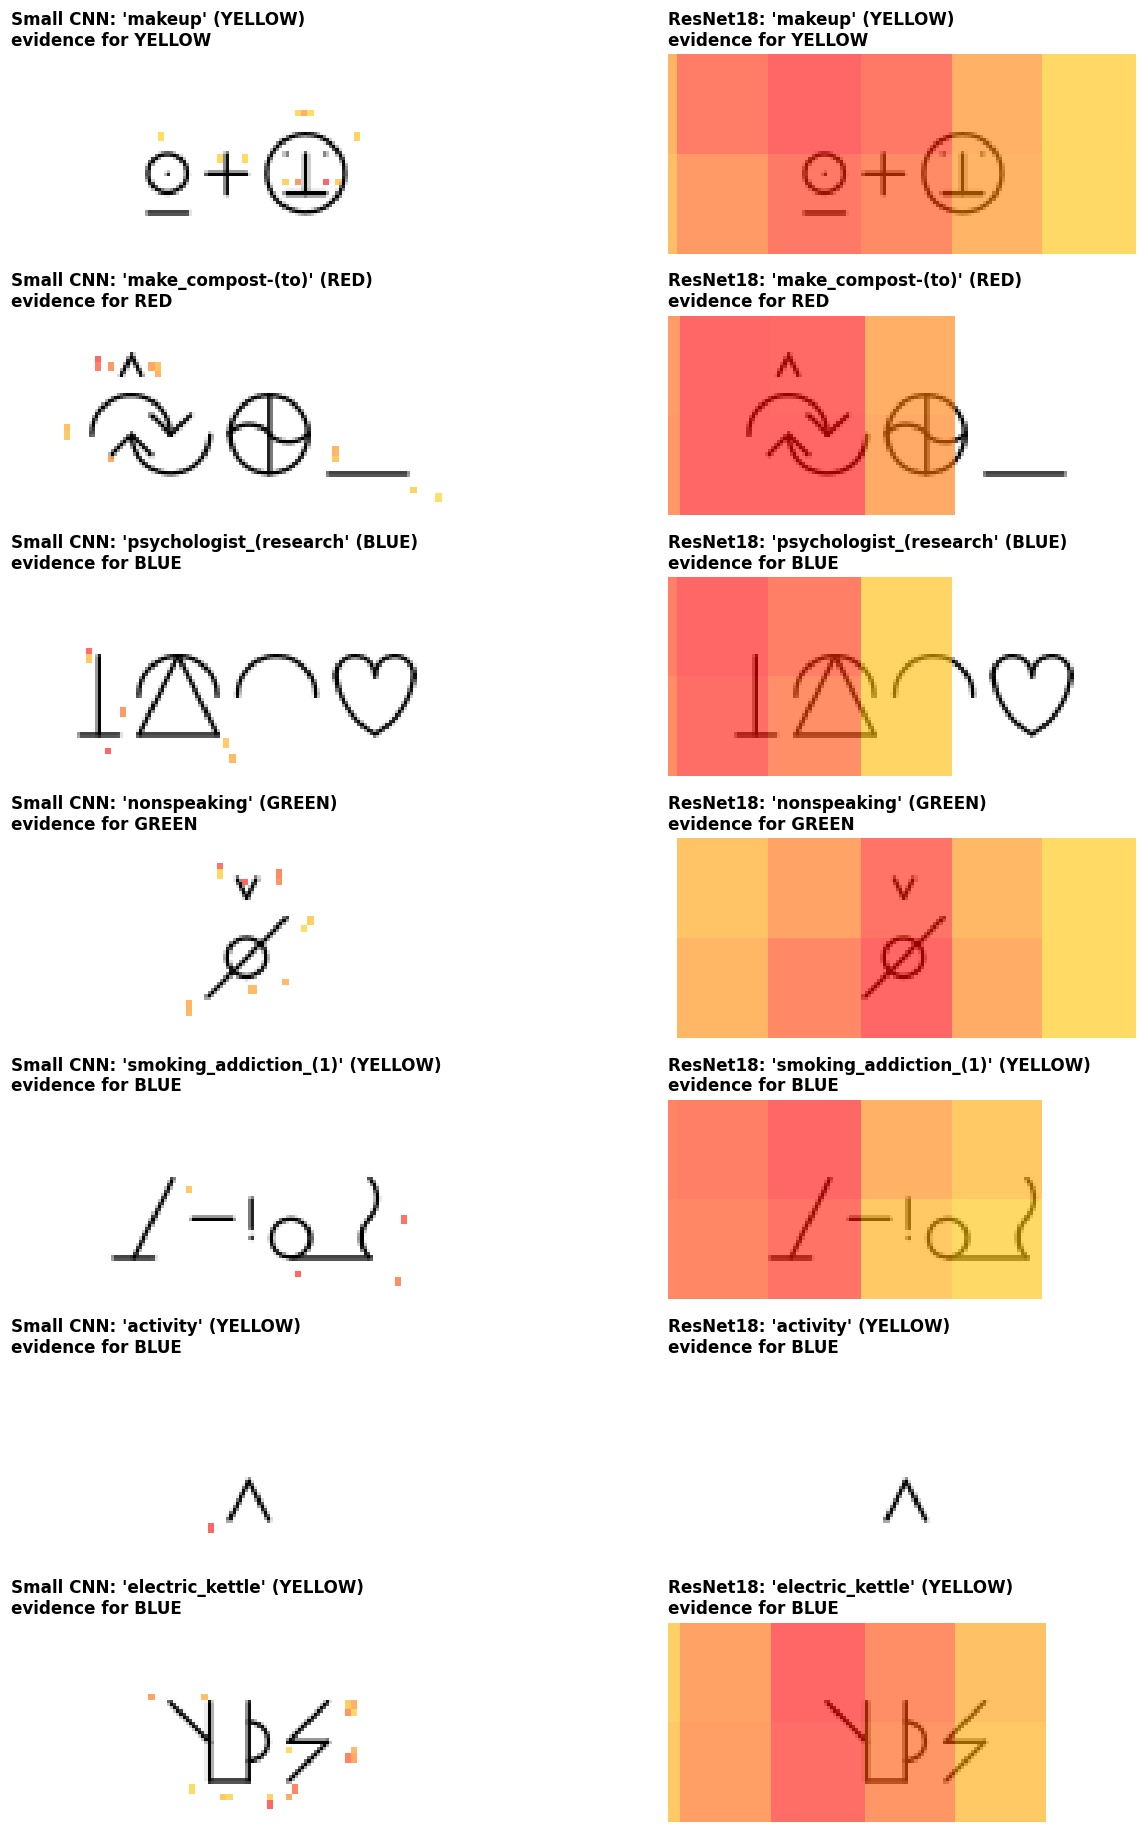

In [38]:
# `intent: Grad-CAM on CNN: does it look at the indicator mark?` -> T8 (Captum LayerGradCam on the last conv layer)
from captum.attr import LayerGradCam, LayerAttribution      # T8
def gradcam_maps(model, layer, X, target):
    layer_gc = LayerGradCam(model, layer)                    # T8: "the last convolution layer ... is the recommended use case for GradCAM"
    attr = layer_gc.attribute(X.to(device), target)          # T8: attribution for one class
    upsampled_attr = LayerAttribution.interpolate(attr, (64, 264))  # T8: back to image size, so it lines up with the drawing
    return np.clip(upsampled_attr.detach().cpu().numpy()[:, 0], 0, None)  # keep only evidence FOR the class

# (a) the number: share of the CNN's Grad-CAM inside the indicator band, 150 dev symbols per class, explained for their TRUE class
rng = np.random.default_rng(SEED)
rows = []
for c, cls in enumerate(CLASSES):
    idx = rng.choice(dev_idx[y[dev_idx] == c], 150, replace=False)
    X = torch.from_numpy(X_img[idx]).requires_grad_(True)
    maps = gradcam_maps(cnn_final, cnn_final.conv2, X, c)
    share = maps[:, INDICATOR_ROWS, :].sum((1, 2)) / (maps.sum((1, 2)) + 1e-12)  # fraction of the evidence that sits on the band
    rows.append({'class': f'{cls} ({MEANING[cls]})', 'Grad-CAM share in indicator band': round(share.mean(), 2),
                 'vs chance (12.5%)': f'{share.mean() / 0.125:.1f}x'})
band_table = pd.DataFrame(rows)
display(band_table)
# `note: ResNet18's last conv layer outputs only 2 x 9 cells for a 64 x 264 image, so one cell covers 32 rows and cannot resolve an
#  8-row band. ResNet18 is shown as pictures only here; LIME (next cell) measures it at stroke level, like-for-like with the other models.`

# (b) the pictures: one symbol per class, plus 3 YELLOW symbols the CNN calls BLUE (out-of-fold), explained for class BLUE
cnn_oof = results[('cnn', 'cluster')]['oof']
show = [int(rng.choice(dev_idx[(y[dev_idx] == c) & (cnn_oof[dev_idx] == c)])) for c in range(4)]
show += list(rng.choice(dev_idx[(y[dev_idx] == 0) & (cnn_oof[dev_idx] == 2)], 3, replace=False))
targets = [y[k] for k in show[:4]] + [CLASSES.index('BLUE')] * 3
fig, axes = plt.subplots(len(show), 2, figsize=(13, 2.4 * len(show)))
for r, (k, t) in enumerate(zip(show, targets)):
    for col, (model, layer, ch, title) in enumerate([(cnn_final, cnn_final.conv2, 1, 'Small CNN'),
                                                    (resnet_final, resnet_final.layer4, 3, 'ResNet18')]):
        X = make_loader(np.array([k]), False, channels=ch).dataset[0][0][None].requires_grad_(True)  # the exact input the model sees
        m = gradcam_maps(model, layer, X, int(t))[0]
        ax = axes[r, col]
        cols = np.where((images[k] < 128).any(axis=0))[0]; x0 = max(0, (cols.min() + cols.max()) // 2 - 75)  # 150-px window around the drawing
        ax.imshow(images[k][:, x0:x0 + 150], cmap='gray')
        m = m / (m.max() + 1e-12)                            # 0..1 within this symbol
        ax.imshow(np.ma.masked_less(m, 0.2)[:, x0:x0 + 150], cmap='autumn_r', alpha=0.6, vmin=0, vmax=1)  # colour only the strongest evidence (top 80% of the range)
        ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(f"{title}: '{labels['english'].iloc[k].split(',')[0][:22]}' ({CLASSES[y[k]]})\nevidence for {CLASSES[int(t)]}", fontsize=11, loc='left')
        for sp in ax.spines.values(): sp.set_visible(False)
fig.tight_layout(); fig.savefig(os.path.join(RESULTS_DIR, 'gradcam_examples.png'), dpi=200); plt.show()

HOG + SVM: indicator stroke ranked first in 30 of 30 RED/GREEN symbols


HOG + SVM, left-aligned (headline): indicator stroke ranked first in 29 of 30 RED/GREEN symbols


Small CNN: indicator stroke ranked first in 30 of 30 RED/GREEN symbols


ResNet18: indicator stroke ranked first in 30 of 30 RED/GREEN symbols


ResNet18, softened (headline): indicator stroke ranked first in 30 of 30 RED/GREEN symbols


ResNet18 features + SVM: indicator stroke ranked first in 30 of 30 RED/GREEN symbols


,model,indicator is the most important stroke,share
0,HOG + SVM,30 of 30,1.00
1,"HOG + SVM, left-aligned (headline)",29 of 30,0.97
2,Small CNN,30 of 30,1.00
3,ResNet18,30 of 30,1.00
4,"ResNet18, softened (headline)",30 of 30,1.00
5,ResNet18 features + SVM,30 of 30,1.00


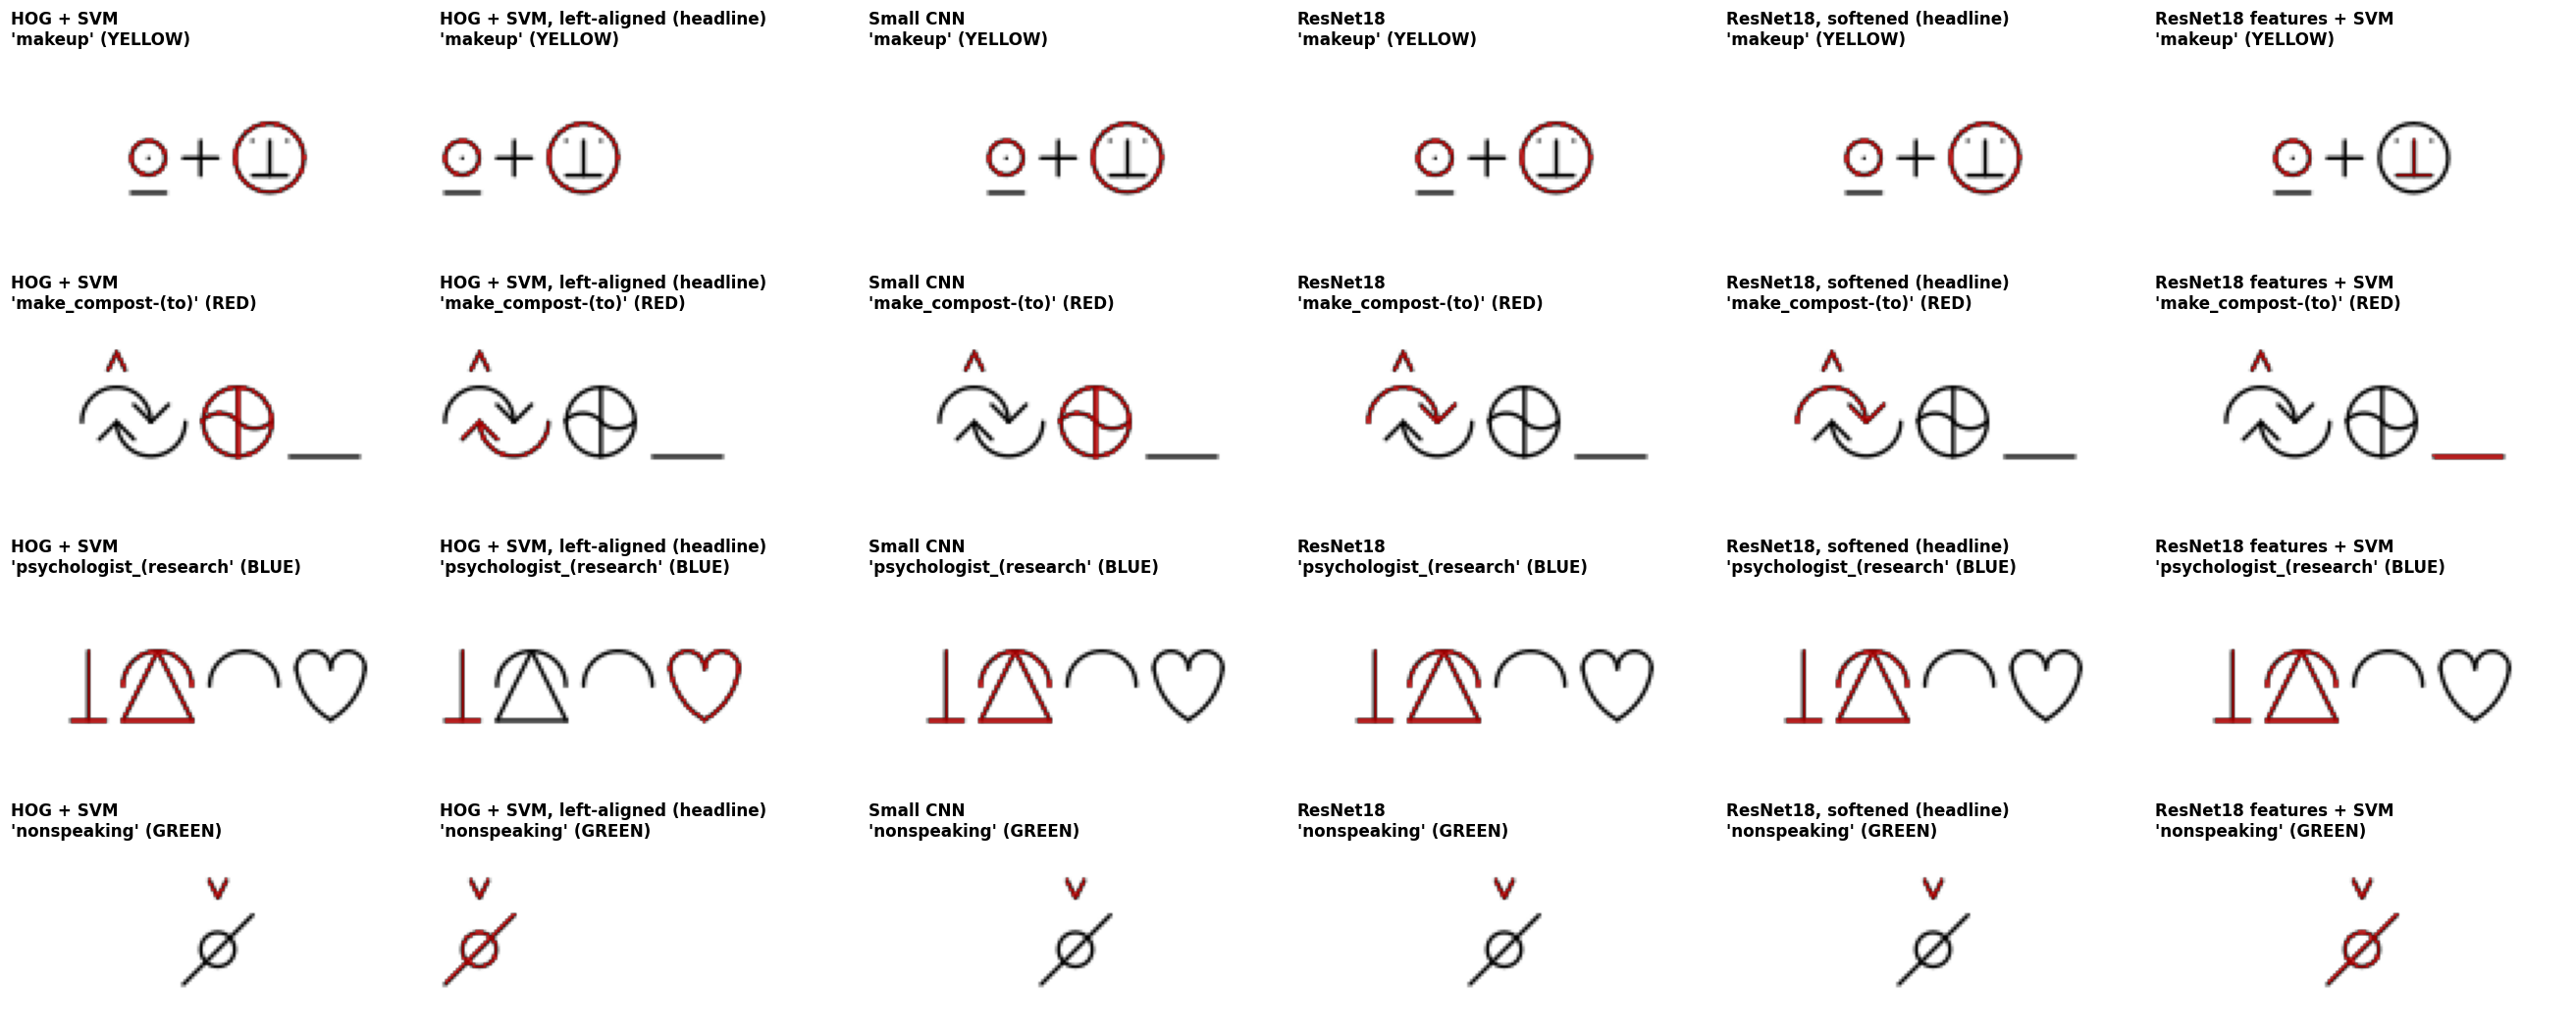

In [39]:
# `intent: LIME on every model for the same symbols, side by side; is the indicator stroke the piece that matters most?` -> T9
# `note: two changes from the T9 tutorial, both needed for line drawings. (1) Pieces = connected ink strokes (skimage.measure.label),
#  because LIME's default segmentation cuts mostly blank paper (tested 2026-10-07). The indicator is a separate stroke, so it is its own piece.
#  (2) hide_color=255: a hidden piece is painted WHITE (erased), not black. For the SVMs the score is decision_function, because
#  SVC(probability=True) is deprecated (T3 extra 2); LIME only needs a score per class. These lines are not in a sourced snippet.`
from lime import lime_image                                  # T9
from skimage.measure import label as stroke_label            # connected strokes
def stroke_segments(rgb):                                    # LIME segmentation_fn: 0 = paper, 1..n = separate strokes
    return stroke_label(rgb[:, :, 0] < 128, connectivity=2)
def to_tensor(imgs, channels):                               # LIME hands over uint8 RGB images; turn them into model input
    a = 1.0 - np.stack(imgs)[:, :, :, 0].astype(np.float32) / 255.0  # ink = 1, paper = 0, as in training
    a = a[:, None] if channels == 1 else np.repeat(a[:, None], 3, axis=1)  # 1 channel, or 3 identical (T17)
    return torch.from_numpy(a).to(device)
def batch_predict_torch(model, channels):                    # T9 batch_predict, for our two networks
    def batch_predict(images_):
        model.eval()                                         # T9
        with torch.no_grad():
            logits = model(to_tensor(images_, channels))     # T9
            probs = F.softmax(logits, dim=1)                 # T9
        return probs.detach().cpu().numpy()                  # T9
    return batch_predict
def predict_svm(imgs):                                       # HOG + SVM: same HOG recipe as section 6
    g = np.array([hog(im[:, :, 0], orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2)) for im in imgs])
    return svm_final.decision_function(g)
def predict_svm_left(imgs):                                  # the same, for the left-aligned SVM (fed left-aligned drawings below)
    g = np.array([hog(im[:, :, 0], orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2)) for im in imgs])
    return svm_left_final.decision_function(g)
def predict_hybrid(imgs):                                    # frozen ResNet18 features (section 7c) + SVM
    with torch.no_grad():
        f = torch.flatten(backbone(to_tensor(imgs, 3))['feat'], 1).cpu().numpy()
    return hybrid_final.decision_function(f)
LIME_MODELS = [('HOG + SVM', predict_svm, images),          # (name, scoring function, the drawings that model was trained on)
               ('HOG + SVM, left-aligned (headline)', predict_svm_left, images_left),
               ('Small CNN', batch_predict_torch(cnn_final, 1), images),
               ('ResNet18', batch_predict_torch(resnet_final, 3), images),
               ('ResNet18, softened (headline)', batch_predict_torch(resnet_soft_final, 3), images),
               ('ResNet18 features + SVM', predict_hybrid, images)]
explainer = lime_image.LimeImageExplainer(random_state=SEED) # T9
import contextlib, io                                        # only to silence LIME's progress bars
def explain(rgb, fn, n):                                     # T9 explain_instance, with its progress bar hidden
    with contextlib.redirect_stderr(io.StringIO()):
        return explainer.explain_instance(rgb, fn, top_labels=4, hide_color=255, num_samples=n,
                                          segmentation_fn=stroke_segments, random_seed=SEED)

def indicator_stroke(seg):                                   # the stroke lying wholly inside the indicator band, if exactly one does
    ids = [s for s in np.unique(seg) if s > 0 and np.all(np.isin(np.where(seg == s)[0], range(10, 22)))]
    return ids[0] if len(ids) == 1 else None

# (a) the number: 15 RED + 15 GREEN dev symbols whose indicator is a separate stroke
cand = [k for k in rng.permutation(dev_idx) if y[k] in (1, 3) and indicator_stroke(stroke_segments(np.stack([images[k]] * 3, -1))) is not None]
pick = [k for k in cand if y[k] == 1][:15] + [k for k in cand if y[k] == 3][:15]
rows = []
for name, fn, src in LIME_MODELS:
    hits = 0
    for k in pick:
        rgb = np.stack([src[k]] * 3, -1)                  # LIME expects a colour image; ours is grey, so 3 identical channels
        explanation = explain(rgb, fn, 300)                  # T9 (300 samples: few pieces per symbol)
        weights = dict(explanation.local_exp[int(y[k])])     # piece -> weight, for the TRUE class
        weights.pop(0, None)                                 # piece 0 is blank paper; hiding it changes nothing, so it is never 'the' evidence
        top = max(weights, key=weights.get)                  # the piece that pushes hardest towards the true class
        hits += int(top == indicator_stroke(explanation.segments))
    rows.append({'model': name, 'indicator is the most important stroke': f'{hits} of {len(pick)}', 'share': round(hits / len(pick), 2)})
    print(f'{name}: indicator stroke ranked first in {hits} of {len(pick)} RED/GREEN symbols', flush=True)
lime_table = pd.DataFrame(rows)
display(lime_table)

# (b) the pictures: the same 4 symbols as Grad-CAM, top 2 strokes FOR the true class highlighted, every model
fig, axes = plt.subplots(4, len(LIME_MODELS), figsize=(24, 10))
for r, k in enumerate(show[:4]):
    for c_, (name, fn, src) in enumerate(LIME_MODELS):
        rgb = np.stack([src[k]] * 3, -1)
        explanation = explain(rgb, fn, 300)                  # T9 (300 samples: few pieces per symbol)
        w = [(seg, wt) for seg, wt in explanation.local_exp[int(y[k])] if seg != 0 and wt > 0]  # strokes pushing FOR the true class, paper excluded
        top2 = [seg for seg, wt in sorted(w, key=lambda t: -t[1])[:2]]  # the two strongest
        mask = np.isin(explanation.segments, top2).astype(int)  # in place of get_image_and_mask, which can pick the paper
        ax = axes[r, c_]
        cols = np.where((src[k] < 128).any(axis=0))[0]; x0 = max(0, (cols.min() + cols.max()) // 2 - 75)  # 150-px window around the drawing
        ax.imshow(src[k][:, x0:x0 + 150], cmap='gray'); ax.imshow(np.ma.masked_equal(mask, 0)[:, x0:x0 + 150], cmap='autumn', alpha=0.6)  # orange = top 2 strokes
        ax.set_xticks([]); ax.set_yticks([])
        for sp in ax.spines.values(): sp.set_visible(False)
        ax.set_title(f"{name}\n'{labels['english'].iloc[k].split(',')[0][:22]}' ({CLASSES[y[k]]})", fontsize=11, loc='left')
fig.tight_layout(h_pad=2.5); fig.savefig(os.path.join(RESULTS_DIR, 'lime_examples.png'), dpi=200); plt.show()

### What the explanations show

- **The models use the mark.** For 30 RED and GREEN symbols whose indicator is a separate stroke, LIME ranked the indicator as the single most important stroke for both headline models: 30 of 30 for ResNet18 (softened) and 29 of 30 for the left-aligned SVM. The other four versions scored 30 of 30. LIME samples at random, so 29 and 30 are the same result: in an earlier run with four models, the hybrid scored 29.
- **Grad-CAM agrees for the small CNN.** For RED symbols, 56% of its attention sits in the indicator band, against 12.5% if attention were spread evenly. That's 4.5 times chance. For GREEN it's 28%.
- **BLUE is recognised by the person shape.** On "psychologist", all six versions highlight the person character at the start.
- **ResNet18's Grad-CAM is too coarse to measure.** Its last layer sees the image as a 2 x 9 grid, so one cell covers half the height. I show it as a picture only and rely on LIME for the like-for-like comparison.

In plain words: the models learned the rule a person would use. That also explains where they fail. When the mark is missing or looks like something else, they fail too. "male gender (in combination)" is a YELLOW symbol drawn as a ^, which is exactly the action mark.

These explanations use each model's final version on symbols it trained on, so they show what the model learned rather than how it generalises.

## 10. Bias and subgroup analysis

Does each model work equally well for every kind of symbol? Subgroups:
- **Indicator mark:** is there ink in the indicator band (rows 12 to 19)? Measured from the drawing itself.
- **Structure:** simple symbols (no parts listed in BCI's derivations) vs symbols built from 2, or 3 or more, parts.
- **Width:** narrow, medium and wide drawings (thirds of the dev set by ink width), since wide compounds pack more into the canvas.

All numbers are out-of-fold on the cluster split. `note: macro F1 inside a subgroup is unstable when a class is nearly absent from it
(simple symbols are 94% YELLOW), so accuracy is shown next to it.`


In [40]:
# `intent: metrics per subgroup for every model` -> T10 (groupby + apply)
parts = pd.read_csv(os.path.join(DATA_DIR, 'parts.csv'))     # part count per symbol, written by make_exclusions.py
n_parts = labels['id'].map(parts.set_index('id')['n_parts']).to_numpy()
ink = images < 128                                           # dark pixels = ink
has_mark = ink[:, INDICATOR_ROWS, :].any(axis=(1, 2))        # any ink in the indicator band
cols = np.where(ink.any(axis=1))                             # (symbol, column) pairs that contain ink
ink_width = np.zeros(len(y), int)
for k in range(len(y)):
    xs = cols[1][cols[0] == k]
    ink_width[k] = xs.max() - xs.min() + 1                   # drawn width in pixels
sub = pd.DataFrame({'class': np.array(CLASSES)[y],
                    'indicator mark': np.where(has_mark, 'mark present', 'no mark'),
                    'structure': np.select([n_parts <= 1, n_parts == 2], ['simple', '2 parts'], '3+ parts'),
                    'width': pd.qcut(ink_width, 3, labels=['narrow', 'medium', 'wide']).astype(str)}).iloc[dev_idx]
for key, title in MODELS:
    sub[key] = results[(key, 'cluster')]['oof'][dev_idx]     # each model's out-of-fold prediction
sub['y'] = y[dev_idx]

def scores(x):                                               # T10: one custom evaluation function, applied to every slice
    out = {'n': len(x), 'YELLOW share': round(np.mean(x['y'] == 0), 2)}
    for key, title in MODELS:
        out[f'{key} acc'] = round(np.mean(x[key] == x['y']), 3)
        out[f'{key} F1'] = round(f1_score(x['y'], x[key], average='macro', labels=range(4), zero_division=0), 3)
    return pd.Series(out)
tables = []
for grouping in ['indicator mark', 'structure', 'width']:
    g1 = sub.groupby(grouping, group_keys=False)             # T10
    t = g1.apply(scores, include_groups=False)               # T10: the custom function on each subgroup
    t.index = [f'{grouping}: {i}' for i in t.index]
    tables.append(t)
subgroup_table = pd.concat(tables)
with pd.option_context('display.max_rows', None):    # every row shown, no '...' gap
    display(subgroup_table.T)                            # one column per subgroup, one row per model score: fits a page


,indicator mark: mark present,indicator mark: no mark,structure: 2 parts,structure: 3+ parts,structure: simple,width: medium,width: narrow,width: wide
n,1635.000,3778.000,3174.000,1361.000,878.000,1476.000,2154.000,1783.000
YELLOW share,0.270,0.900,0.690,0.600,0.940,0.700,0.650,0.780
svm acc,0.930,0.962,0.956,0.937,0.967,0.955,0.969,0.932
svm F1,0.880,0.649,0.931,0.904,0.749,0.927,0.942,0.884
cnn acc,0.916,0.920,0.926,0.902,0.918,0.936,0.929,0.893
cnn F1,0.867,0.414,0.905,0.874,0.608,0.910,0.890,0.869
resnet acc,0.977,0.980,0.983,0.973,0.975,0.980,0.981,0.977
resnet F1,0.963,0.476,0.975,0.962,0.791,0.968,0.964,0.967
hybrid acc,0.878,0.949,0.928,0.913,0.949,0.932,0.936,0.914
hybrid F1,0.842,0.517,0.887,0.877,0.606,0.882,0.889,0.838


In [41]:
# `intent: BLUE recall by how the symbol starts, and the symbols every model gets wrong` -> T10 subgroups; the rest needs no research (numpy)
# `note: BCI lets many characters stand in for "person" at the start of a people-symbol (Fundamental Rules, clause 8.1).
#  starts_with_person comes from BCI's derivations: 1 when the symbol's first part is the person character. Written by make_exclusions.py.`
person_first = labels['id'].map(parts.set_index('id')['starts_with_person']).to_numpy().astype(bool)
blue_dev = dev_idx[y[dev_idx] == 2]                          # every BLUE dev symbol (all have an out-of-fold prediction)
blue_groups = {'starts with the person shape': person_first & (n_parts > 1),
               'starts with another people-shape': ~person_first & (n_parts > 1),
               'single character (no parts)': n_parts <= 1,
               'all not starting with the person shape (6c)': ~person_first}  # the set section 6c's prediction was written about
rows = []
for gname, mask in blue_groups.items():
    sel = blue_dev[mask[blue_dev]]
    rows.append({'BLUE symbols': gname, 'n': len(sel), **{key: round(np.mean(results[(key, 'cluster')]['oof'][sel] == 2), 3) for key, _ in MODELS}})
blue_start = pd.DataFrame(rows).set_index('BLUE symbols')    # share of each group each model calls BLUE (recall)
display(blue_start)

wrong_all = np.ones(len(dev_idx), bool)                      # True until some model gets the symbol right
for key, _ in MODELS:
    wrong_all &= results[(key, 'cluster')]['oof'][dev_idx] != y[dev_idx]
hard = dev_idx[wrong_all]
print(f'{len(hard)} dev symbols are wrong for all {len(MODELS)} models (out-of-fold, cluster split). The first few:')
for k in hard[:8]:
    print(f"  '{labels['english'].iloc[k].split(',')[0]}': BCI says {CLASSES[y[k]]}, ResNet18 (softened) says {CLASSES[results[('resnet_soft', 'cluster')]['oof'][k]]}")

,n,svm,cnn,resnet,hybrid,cnn_soft,svm_soft,resnet_soft,svm_left,cnn_left,resnet_left
BLUE symbols,,,,,,,,,,,
starts with the person shape,193,0.865,0.964,1.000,0.798,0.938,0.917,0.995,0.969,0.995,0.995
starts with another people-shape,234,0.679,0.850,0.940,0.718,0.791,0.675,0.923,0.816,0.868,0.927
single character (no parts),52,0.769,0.865,0.827,0.712,0.731,0.635,0.808,0.731,0.827,0.827
all not starting with the person shape (6c),286,0.696,0.853,0.920,0.717,0.780,0.668,0.902,0.801,0.860,0.909


26 dev symbols are wrong for all 10 models (out-of-fold, cluster split). The first few:
  'be_caused_by-(to)': BCI says RED, ResNet18 (softened) says YELLOW
  'metaphor': BCI says YELLOW, ResNet18 (softened) says BLUE
  'reclining': BCI says BLUE, ResNet18 (softened) says YELLOW
  'devil_(2)': BCI says BLUE, ResNet18 (softened) says YELLOW
  'angel_(2)': BCI says BLUE, ResNet18 (softened) says YELLOW
  'Holy_Infant': BCI says BLUE, ResNet18 (softened) says YELLOW
  'Holy_Trinity': BCI says YELLOW, ResNet18 (softened) says BLUE
  'jury': BCI says YELLOW, ResNet18 (softened) says BLUE


### What the subgroups show

- **Wide symbols and symbols built from 3 or more parts are harder** for the SVM, the CNN and the hybrid. The original HOG + SVM drops from 0.969 accuracy on narrow symbols to 0.932 on wide ones.
- **Left-aligning fixed most of that.** The left-aligned SVM scores 0.978 on narrow and 0.971 on wide symbols. So the change that made it more accurate also made it fairer.
- **ResNet18 is flat across every subgroup** (0.971 to 0.987 accuracy), whatever the width, the number of parts or whether there's a mark.
- **BLUE is the weak class for everyone.** BCI lets many different characters stand in for "person" as the first character (man, woman, God, doctor, group...). The original, centred SVM found only 68% of BLUE symbols that start with one of those other people-shapes. Left-aligned it finds 82%, and ResNet18 (softened) 92% (table above).
- **Single-character symbols are the hardest BLUE cases.** The softened, centred SVM finds 63% of them, left-aligned 73%, and ResNet18 (softened) 81%. There's no classifier character to read, just one shape.

The macro F1 inside a subgroup jumps around when a class is nearly missing from it (simple symbols are 94% YELLOW), which is why I read accuracy next to it.

## 11. Who this helps

Nouh asked me a fair question on our call: who would actually use this, and who would pay for it? He gave the NHS as the example for medical work. Here's my honest answer, and it starts with what the model isn't.

**What it isn't.** It isn't something a non-speaking person uses to talk. It doesn't pick words or speak for anyone. It reads a drawing and says which word class the drawing looks like. So the people it helps directly are the ones who make and look after Bliss symbols. The people who use Bliss every day benefit one step removed.

**Who would use it, and why**
- **BCI, who maintain the vocabulary.** This is the strongest fit. The vocabulary already has over 6,500 symbols and grows with each release, and every new symbol is colour coded by hand. The model can check each new drawing against its colour and flag the ones that disagree. My duplicate check has already turned up one case like this: "improve" (RED) and "improvement" (YELLOW) are the same drawing with different colours. That's exactly the kind of symbol a person should look at.
- **People who design new Bliss symbols.** When someone proposes a new symbol, the model can suggest a class from the drawing alone. If its suggestion disagrees with the class the designer meant, the drawing might be missing its action or description mark. That's useful because in Bliss the drawing is meant to carry the class (BCI Fundamental Rules, clauses 6.3 and 8.1).
- **AAC software companies.** Companies that ship symbol libraries in their apps have the same problem at a bigger scale. Karlsson (2026), working with Tobii Dynavox, describes keeping large symbol libraries labelled as slow manual work that drifts between annotators. A model that checks labels against drawings takes some of that load.
- **Speech and language therapists and AAC services,** including the specialist AAC services in the NHS. When they build a communication board for someone, a quick check that every symbol carries the right colour keeps the board consistent.
- **Non-speaking Bliss users and their families.** They never touch the model. What they get is a vocabulary with fewer mistakes in it, and the colour code is only worth having if it's consistent.

**Who would pay for it.** Being realistic, this isn't an NHS-scale product on its own. It's a narrow tool for a small community. The good news is it doesn't need much money. The SVM runs on an ordinary laptop with no GPU (section 13), so the cost of adopting it is close to nothing. The likely routes are:
- **BCI or a symbol software company** adopting it as an in-house check on each new release.
- **A research partnership.** The Inclusive Design Research Centre (IDRC), who built Baby Bliss Bot, already work on AI for Bliss, so they're a natural partner. Nouh has also offered to help me publish this.
- **The NHS and similar services** benefit, because they fund AAC for the people who use it. I can't see them funding a tool this narrow by itself, though. It's more likely to come in as one part of bigger AAC work, such as the next step in section 14: combining the drawing with the word's meaning.

## 12. Ethics

**Who this is for.** Section 11 covers who would use this. For ethics, the point is that the people most affected by a mistake, non-speaking Bliss users, are the furthest away from the model. They'd never see it, so they can't catch its errors. That's a big part of why a person has to stay in the loop.

**Privacy.** There is no personal data here. The dataset is a published vocabulary of drawings, released under CC BY-SA 4.0. I credit BCI, and anything I share from it goes out under the same licence.

**Research integrity.** This dataset overlaps with another study of mine. The 223 symbols that study holds back for its own test were removed before this work began, so neither result can leak into the other.

**The cost of a wrong answer.** A model like this would suggest or check a word class. It wouldn't speak for anyone. Even so, mistakes aren't equal.
- Calling a person a thing is the worst kind. BLUE (people) is exactly the class every model struggles with most, and on the test set the headline deep model missed a whole family of gods.
- A model trained on this vocabulary carries its biases. BCI's vocabulary has its own history, so whole groups of symbols (the Norse gods are one example) can sit in the data as a single family. If a family is missing from training, the model can fail on all of it at once, and an average score would hide that.
- Some symbols can't be classified from the drawing at all (26 beat every model). A tool must not pretend otherwise.

**So a human stays in the loop.** The model should flag and suggest, and a person decides. Its weak spots should be published with it: BLUE, single-character symbols and unseen families.

**Being honest about the evidence.** Every fix was written down before it ran, the test set was opened once, and when the result went against me (the Norse gods) I reported it instead of switching models.

## 13. Deployment

I didn't deploy this, but here's how I would, and which model I'd pick.

**The use case.** The first job I'd build is the quality check for BCI from section 11. When BCI adds or edits symbols, the model reads each new drawing and flags any whose colour code disagrees with what the drawing suggests. It runs once per release, so it's a batch job, not a live one, which keeps it simple and cheap.

**Which model.** It's a trade-off, and both headline models are level on accuracy.
- **HOG + SVM (left-aligned)** needs no GPU to train or run, and every step can be explained. It's slower per symbol (about 4.8 ms) and larger (69 MB), but for a batch of a few hundred new symbols that's seconds.
- **ResNet18** is faster per symbol on a GPU (about 0.8 ms) and the most even across subgroups, but it needs a GPU to train, and I only timed it on one.

For a small organisation checking a few hundred symbols a year, I'd ship the SVM. It's cheap, explainable and runs anywhere. This is Nouh's point about cost: don't reach for deep learning if a classical model does the job.

**How it would run.** Package the model with its preprocessing (render, left-align, HOG) behind a small API or a command-line tool. Run it on each new BCI release, write a report of flagged symbols, and let a person review them.

**Keeping it honest.** Monitor how often reviewers overrule it, by class. Retrain when BCI publishes a new release, using the same family split and a fresh held-out set. Watch BLUE closely, because a new family of people-symbols is exactly what tripped the model up here.

## 14. Reflection, limitations and next steps

**What I learned.**
- Domain knowledge beat model size. The biggest single gain (+0.032) came from understanding how Bliss is written: the first character sets the category, so put it in the same place every time.
- One loss setting can matter more than the model type. Softening the class weights moved the small CNN by 0.027 (the paired-test table in section 8), close to the 0.032 gap between the original SVM and CNN.
- Some of my own explanations were wrong, and the data showed it. I first thought the small CNN struggled with unseen families; softening its weights removed most of that gap, so it was the loss, not the families. I predicted left-aligning wouldn't help single-character symbols; it did, because position matters for every shape, not just the classifier.
- Writing the rule down before running an experiment kept me honest. Without it, the Norse gods result would have been very tempting to explain away.

**Limitations.**
- The colour meanings come from reading the data. I haven't found BCI's own written key.
- The test set is small for the rare classes (53 BLUE symbols), so one family can swing it.
- Timings come from different hardware, so the cost comparison shows a shape, not exact numbers.
- Explanations are run on symbols the final models trained on.

**Next steps.**
- Combine the drawing with the symbol's English word. The 26 symbols no model can get right take their class from meaning, and that's where my dissertation's language work comes in.
- Test left-alignment and the family split on other symbol sets such as ARASAAC.
- Look at why softened weights hurt ResNet18 on the unseen family, with a second family held out on purpose.

## 15. References

**Data and Bliss**

1. Blissymbolics Communication International (2026). *BCI Authorised Vocabulary (BCI-AV)*, July 2026 release. CC BY-SA 4.0. https://www.blissymbolics.org/
2. BCI Fundamental Rules Working Group (2003). *The fundamental rules of Blissymbolics: creating new Blissymbolics characters and vocabulary*. Blissymbolics Communication International. https://www.evertype.com/standards/by/bliss-rules-20030921.pdf (clauses 6.3, 6.3.1 and 8.1)
3. Inclusive Design Research Centre (n.d.). *Baby Bliss Bot*. GitHub repository. https://github.com/inclusive-design/baby-bliss-bot (image preparation: docs/PrepareImageSetForStyleGAN.md)

**Related work**

4. Netzer, Y. (2006). *Semantic Authoring for Blissymbols Augmented Communication Using Multilingual Text Generation*. PhD thesis, Ben-Gurion University of the Negev.
5. Caironi, N. (2024). *Comparative Analysis of Image Generation Models for Symbol Generation in Augmentative and Alternative Communication*. Master's thesis (Laurea Magistrale), Computer Science and Engineering, Politecnico di Milano. Advisor: Prof. Christian Pilato.
6. Karlsson, L. (2026). *AI-Driven Multi-Label Attribute Prediction for Augmentative and Alternative Communication Symbols*. MSc thesis, Örebro University. https://www.diva-portal.org/smash/get/diva2:2103094/FULLTEXT01.pdf
7. Singer, J. J. D., Seeliger, K., Kietzmann, T. C. and Hebart, M. N. (2022). From photos to sketches: how humans and deep neural networks process objects across different levels of visual abstraction. *Journal of Vision*, 22(2). https://doi.org/10.1167/jov.22.2.4
8. Wang, H., Ge, S., Xing, E. P. and Lipton, Z. C. (2019). Learning Robust Global Representations by Penalizing Local Predictive Power. arXiv:1905.13549.

**Methods**

9. Dalal, N. and Triggs, B. (2005). Histograms of Oriented Gradients for Human Detection. *CVPR 2005*, pages 886 to 893. https://doi.org/10.1109/CVPR.2005.177
10. Blondel, V. D., Guillaume, J.-L., Lambiotte, R. and Lefebvre, E. (2008). Fast unfolding of communities in large networks. *Journal of Statistical Mechanics: Theory and Experiment*, P10008.
11. Smith, L. N. (2017). Cyclical Learning Rates for Training Neural Networks. *WACV 2017*. arXiv:1506.01186.
12. Cui, Y., Jia, M., Lin, T.-Y., Song, Y. and Belongie, S. (2019). Class-Balanced Loss Based on Effective Number of Samples. *CVPR 2019*, pages 9260 to 9269.
13. He, K., Zhang, X., Ren, S. and Sun, J. (2015). Deep Residual Learning for Image Recognition. arXiv:1512.03385.
14. Razavian, A. S., Azizpour, H., Sullivan, J. and Carlsson, S. (2014). CNN Features off-the-shelf: an Astounding Baseline for Recognition. arXiv:1403.6382.
15. Ribeiro, M. T., Singh, S. and Guestrin, C. (2016). "Why Should I Trust You?": Explaining the Predictions of Any Classifier. arXiv:1602.04938.
16. Selvaraju, R. R., Cogswell, M., Das, A., Vedantam, R., Parikh, D. and Batra, D. (2019). Grad-CAM: Visual Explanations from Deep Networks via Gradient-based Localization. *International Journal of Computer Vision*. arXiv:1610.02391.
17. Yeh, A. (2000). More accurate tests for the statistical significance of result differences. *COLING 2000*. arXiv:cs/0008005.